# 5.1. pandas: Basics

Module M-227-04: Programming for Data Analytics

Instructor: Nadežda Zeņina

Course author: Dmitry Pavlyuk

## Previous lesson review

Warm-up: *Check yourself 5.1 - weeks 1-4 recap*

## Today

**Goal:** by the end of the lesson you can load a data set, inspect its structure, select and filter records, calculate basic statistics and draw a simple chart - and answer one question about real data: *does the weather influence how many bikes people rent?*

1. **Why pandas** - tables are the natural shape of data; pandas vs NumPy
2. **Loading / saving data** - `read_csv`, `read_excel`, `read_html`, ... and `to_csv`
3. **Data structures** - `Series` (one column) and `DataFrame` (a table)
4. **Data types** of columns - `dtypes`
5. **Indexing** - row labels, `set_index` / `reset_index`, `reindex`
6. **Selectors** - `.loc` (labels), `.iloc` (positions), filtering with conditions
7. **Sorting** - by index and by values
8. **Transforming columns** - new columns, `apply`, `map`, dropping
9. **Statistics** - `mean`, `describe`, `corr`
10. **Plots** - straight from the DataFrame

## pandas

__pandas__ is a fast, powerful, flexible and easy to use open source data analysis and manipulation tool,
built on top of the Python programming language.

McKinney (the author of the base book for this course, Python for Data Analysis: Data Wrangling with pandas, NumPy, and Jupyter) is one of the founding developers of this library

Almost all data you will meet in analytics is a **table**: an Excel sheet, a CSV export, a database query, a web page with results. Columns have **names** and **different types** (dates, text, numbers), rows are **records**, some values are **missing**. A NumPy array (one dtype, positions only) is too strict for that. pandas is the "Excel inside Python"

The same numbers as a NumPy array and as a pandas DataFrame - names, mixed types and an index are added
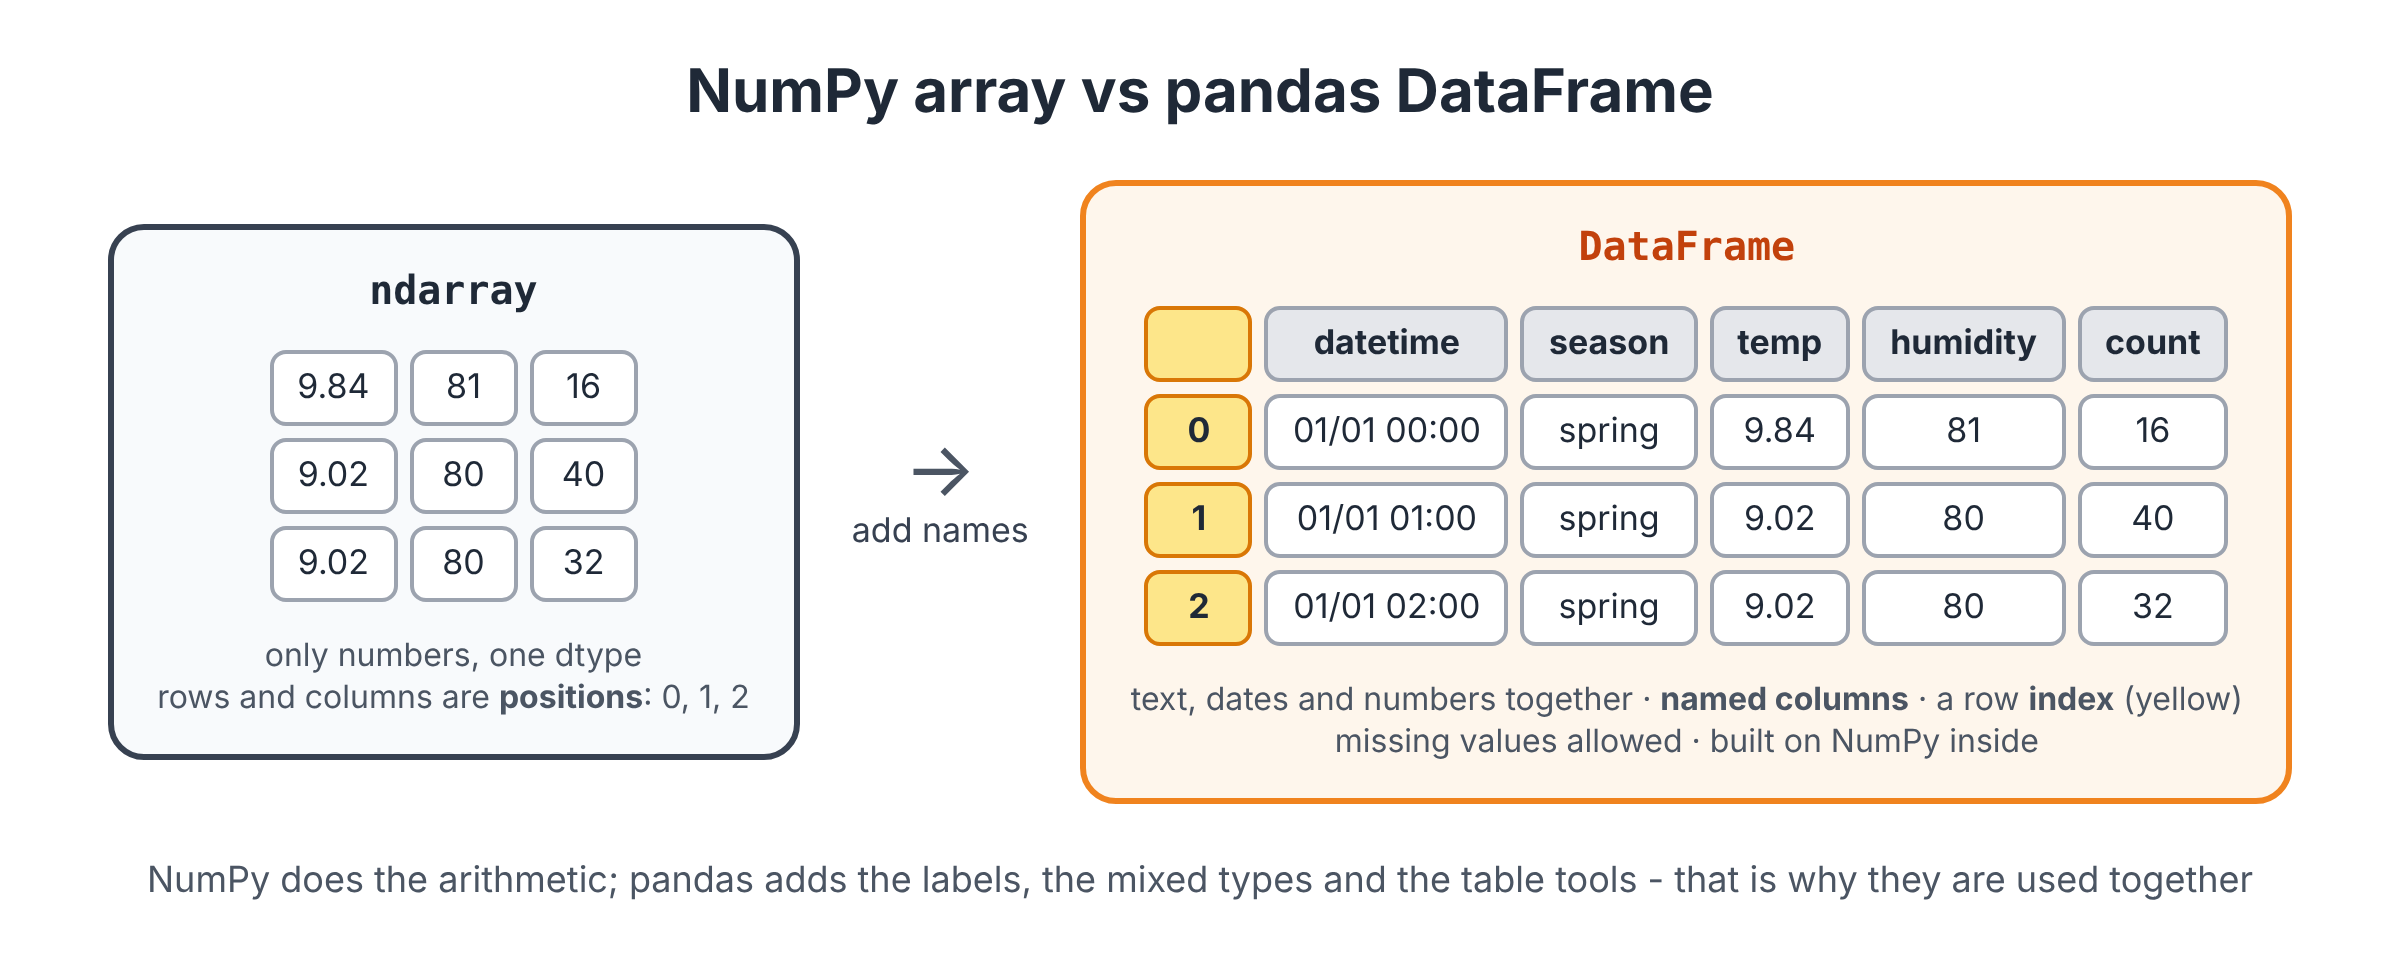

Like NumPy, pandas is a **third-party library** - installed once with `pip` (in Google Colab it is already there, the cell below only confirms that). The standard short name is `pd`.

In [106]:
!pip install pandas

In [107]:
import pandas as pd
print(pd.__version__)

2.2.3


## pandas vs numpy

|                 | NumPy                                          | pandas                                    |
|-----------------|------------------------------------------------|-------------------------------------------|
| Data            | Homogeneous                                    | Heterogeneous                             |
| Primary objects | ndarray                                        | DataFrame, Series                         |
| Indexing        | By position                                    | By position and index                     |
| Memory          | Efficient                                      | Larger                                    |
| Speed           | Faster for arrays of several thousand elements | Faster for arrays of millions of elements |
| Primary purpose | Calculations                                   | Data wrangling                            |

Usually the packages are used together!

## Loading / Saving Data

One pd.read_xxx() call brings a file into a DataFrame; one df.to_xxx() call writes it back
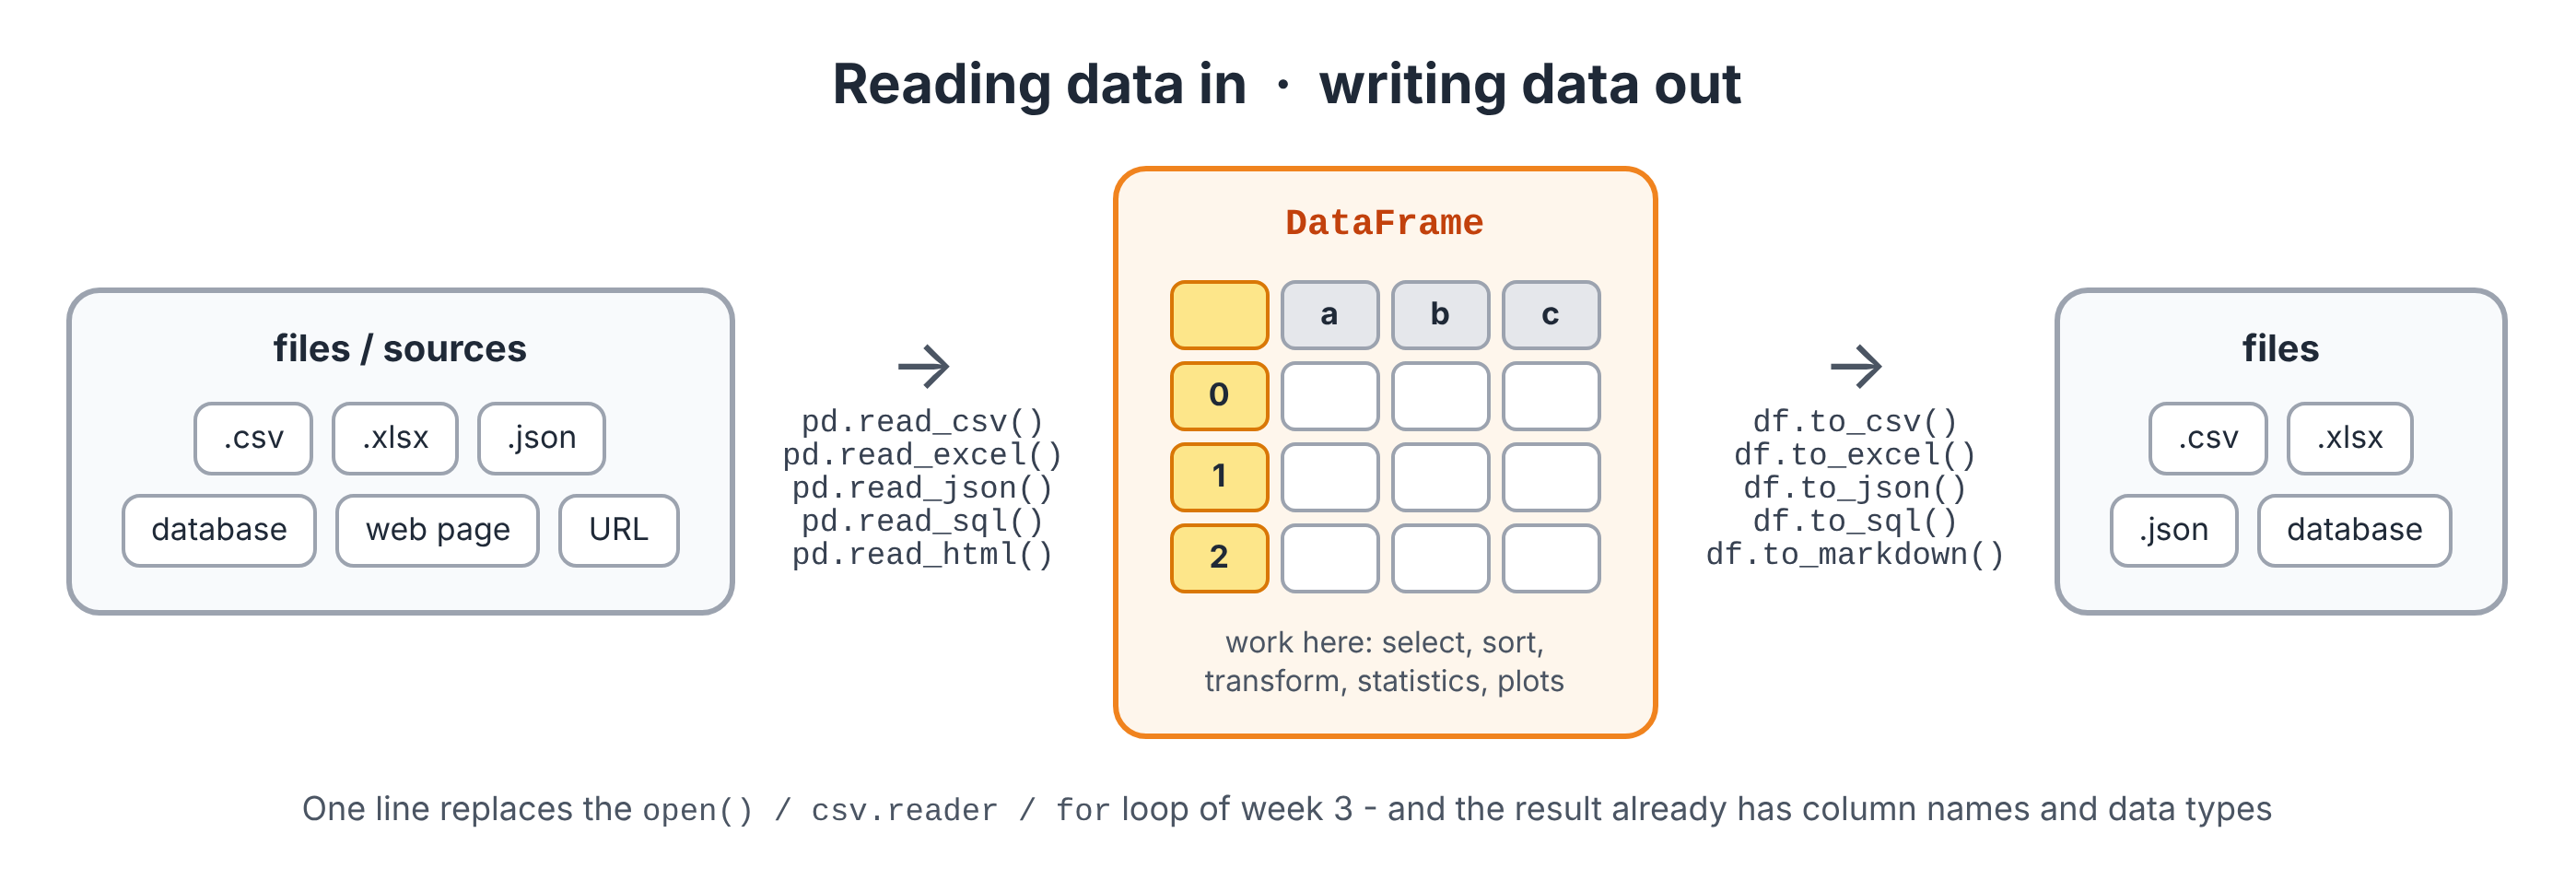

### Loading data to pandas

* from CSV __read_csv__
* from XLS, XLSX __read_excel__
* from JSON __read_json__
* from databases __read_sql__
* from HTML __read_html__

Methods work not only for local files, but also accept URLs

Compare with week 3, where we opened a CSV file, read it line by line with `csv.reader` and converted every value by hand. `pd.read_csv` does all of that in one line **and** recognises the column names and the data types.

### Example data set: Bike Sharing Demand

Source: Kaggle machine learning competition
URL: https://www.kaggle.com/competitions/bike-sharing-demand/overview/description

* __datetime__ - hourly date + timestamp
* __season__ -  spring / summer / fall / winter
* __holiday__, __workingday__- whether the day is considered a holiday/workingday
* __weather__
    * 1: Clear, Few clouds, Partly cloudy, Partly cloudy
    * 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
    * 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
    * 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
* __temp__ and __atemp__- temperature and "feels like" temperature in Celsius
* __humidity__ - relative humidity
* __windspeed__ - wind speed
* __casual__, __registered__, __count__ - number of non-registered / registered / total user rentals initiated

Every row is **one hour** of a bike-rental system in Washington DC (2011-2012): the weather in that hour and how many bikes were rented. We will use this table for the whole lesson and for Lab 5.

**Question of the day:** *does the temperature influence how many bikes are rented?* Keep it in mind - we answer it at the end of the lesson with the tools learned on the way.

### Loading Bike Sharing Demand Data

The file lives in the course repository. In Colab we first download it into a `data` folder (as we did in 3.2 with `urlretrieve`) - then the loading line is the same as on a local computer. `.head()` shows the **first 5 rows** - always the first thing to do with new data.

In [108]:
bikes = pd.read_csv('/content/bikes.csv')
bikes.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,01/01/2011 00:00,spring,0,0,1,9.84,14.395,81,0.0,3,13,16
1,01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32,40
2,01/01/2011 02:00,spring,0,0,1,9.02,13.635,80,0.0,5,27,32
3,01/01/2011 03:00,spring,0,0,1,9.84,14.395,75,0.0,3,10,13
4,01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0,0,1,1


### First look at a new table

Commands you will type every time you open a data set:

In [109]:
print(bikes.shape)          # (rows, columns) - as for a NumPy array
bikes.tail(3)               # the last 3 rows

(10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
10883,19/12/2012 21:00,winter,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,19/12/2012 22:00,winter,0,1,1,13.94,17.425,61,6.0032,12,117,129
10885,19/12/2012 23:00,winter,0,1,1,13.12,16.665,66,8.9981,4,84,88


In [110]:
bikes.info()                # column names, how many non-missing values, data types, memory

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  object 
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(7), object(2)
memory usage: 1020.7+ KB


`info()` already answers three questions: *how many rows?* (10 886), *are there missing values?* (every column has 10 886 non-null values - no gaps here) and *which columns are text?* (`object` = text: `datetime` and `season`).

Never assume a data set is complete - **check** it. `isna()` marks every missing cell with `True`, `.sum()` counts them per column:

In [111]:
bikes.isna().sum()          # 0 everywhere - this data set has no gaps; real exports usually do

,0
datetime,0
season,0
holiday,0
workingday,0
weather,0
temp,0
atemp,0
humidity,0
windspeed,0
casual,0


### Loading HTML data

`read_html` reads **every `<table>` on a web page** and returns a *list* of DataFrames. Here we take the classified-ads site ss.lv (BMW cars), find the largest table and look at it. (Needs internet access)

In [112]:
ss_bmw = pd.read_html('https://www.ss.lv/lv/transport/cars/bmw/sell/', header=0)
print(len(ss_bmw))
main_table = sorted(ss_bmw,key=lambda x:len(x), reverse=True)[0]
main_table.head()

8


,Sludinājumi \tdatums,Sludinājumi \tdatums.1,Sludinājumi \tdatums.2,Modelis,Gads,Tilpums,Nobraukums,Cena
0,NaN,NaN,"Pārdodu BMW 525d E60, 2004. gada. Virsū labas ...",525,2004,2.5D,257 tūkst.,"4,100 €"
1,NaN,NaN,"Pārdodu BMW X1 E84, sDrive, 2010 gada, 2.0dīze...",X1,2010,2.0D,344 tūkst.,"5,199 €"
2,NaN,NaN,Bmw 320D Lci B47 140kw Sport Line Facelift Aut...,320,2016,2.0D,123 tūkst.,"13,950 €"
3,NaN,NaN,Tikai Rakstit Whatsapp. Nesen izieta tehniska ...,330,2006,3.0D,380 tūkst.,"4,990 €"
4,NaN,NaN,"BMW f10 M-pakete, nesen ievest. 3.0d ar 190kw ...",530,2012,3.0D,323 tūkst.,"8,400 €"


What happened in the line with `sorted(...)`: `len(x)` is the number of rows of a table, so `sorted(..., key=len, reverse=True)` orders the tables from the largest to the smallest, and `[0]` takes the largest one - the list of advertisements.

In [113]:
# OPTIONAL - the same with a Wikipedia page:
url = "https://en.wikipedia.org/wiki/List_of_European_countries_by_population"
wiki = pd.read_html(url, storage_options={"User-Agent": "IntroDataAnalytics/1.0"})
print(len(wiki), "tables found")
wiki[1].head()

3 tables found


,Unnamed: 0,Location,UN estimate (2025),% change,Official figure,Official date,Notes
0,NaN,Europe,744398832,NaN,NaN,NaN,NaN
1,1 T,Russia,143997393,−0.6%,146150789.0,1 Jan 2024[4],[a]
2,2 T,Turkey,87685426,0.3%,85664944.0,31 Dec 2024[5],NaN
3,3,Germany,84075074,−0.6%,83510950.0,30 Jun 2024[6],NaN
4,4,United Kingdom,69551332,0.6%,68265209.0,30 Jun 2023[7],[b]


## Loading data - options

.read_xxx has many parameters (50+) for

* Indexing - get column/row names from the file, arguments you provide, or not at all.
* Type inference and data conversion - including the user-defined value conversions, list of missing value markers, etc.
* Date and time parsing - parsing format, including merging several columns
* Iterating - support for iterating over chunks of very large files.
* Unclean data issues - skipping rows, comments, or other minor things like numeric data with thousands separated by commas
* Dialects (e.g., CSV dialect)

You do not need to remember them - you need to know they exist. The ones used most often: `sep=';'` (Latvian Excel exports use a semicolon), `decimal=','`, `index_col=0`, `usecols=[...]`, `nrows=100`, `na_values=['-', 'n/a']`. Optional example - read only three columns and only the first 5 rows:

In [114]:
# OPTIONAL
small = pd.read_csv('/content/bikes.csv', usecols=['datetime', 'temp', 'count'], nrows=10)
small

,datetime,temp,count
0,01/01/2011 00:00,9.84,16
1,01/01/2011 01:00,9.02,40
2,01/01/2011 02:00,9.02,32
3,01/01/2011 03:00,9.84,13
4,01/01/2011 04:00,9.84,1
5,01/01/2011 05:00,9.84,1
6,01/01/2011 06:00,9.02,2
7,01/01/2011 07:00,8.20,3
8,01/01/2011 08:00,9.84,8
9,01/01/2011 09:00,13.12,14


## Saving data

Very straightforward using __.to_XXX__ methods:
* .to_csv()
* .to_excel()
* .to_sql()
* .to_markdown()

In [115]:
bikes.head(10).to_csv('bikes_first10.csv', index=False)     # index=False: do not write the 0,1,2,... column
bikes.head(10).to_excel('bikes_first10.xlsx', index=False)  # Colab: see the file in the folder icon on the left
print(open('bikes_first10.csv').read()[:300])

datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
01/01/2011 00:00,spring,0,0,1,9.84,14.395,81,0.0,3,13,16
01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32,40
01/01/2011 02:00,spring,0,0,1,9.02,13.635,80,0.0,5,27,32
01/01/2011 03:00,spring,0,0,1,9.


## Pandas Data Structures

### Series and Dataframes

* __Series__
    * 1D array
    * Homogeneous
    * size immutable
* __DataFrame__
    * list of Series
    * 2D array
    * Heterogeneous
    * size mutable
* __Panel__
    * 3D array
    * Deprecated

A Series is one labelled column; a DataFrame is several Series that share the same row index
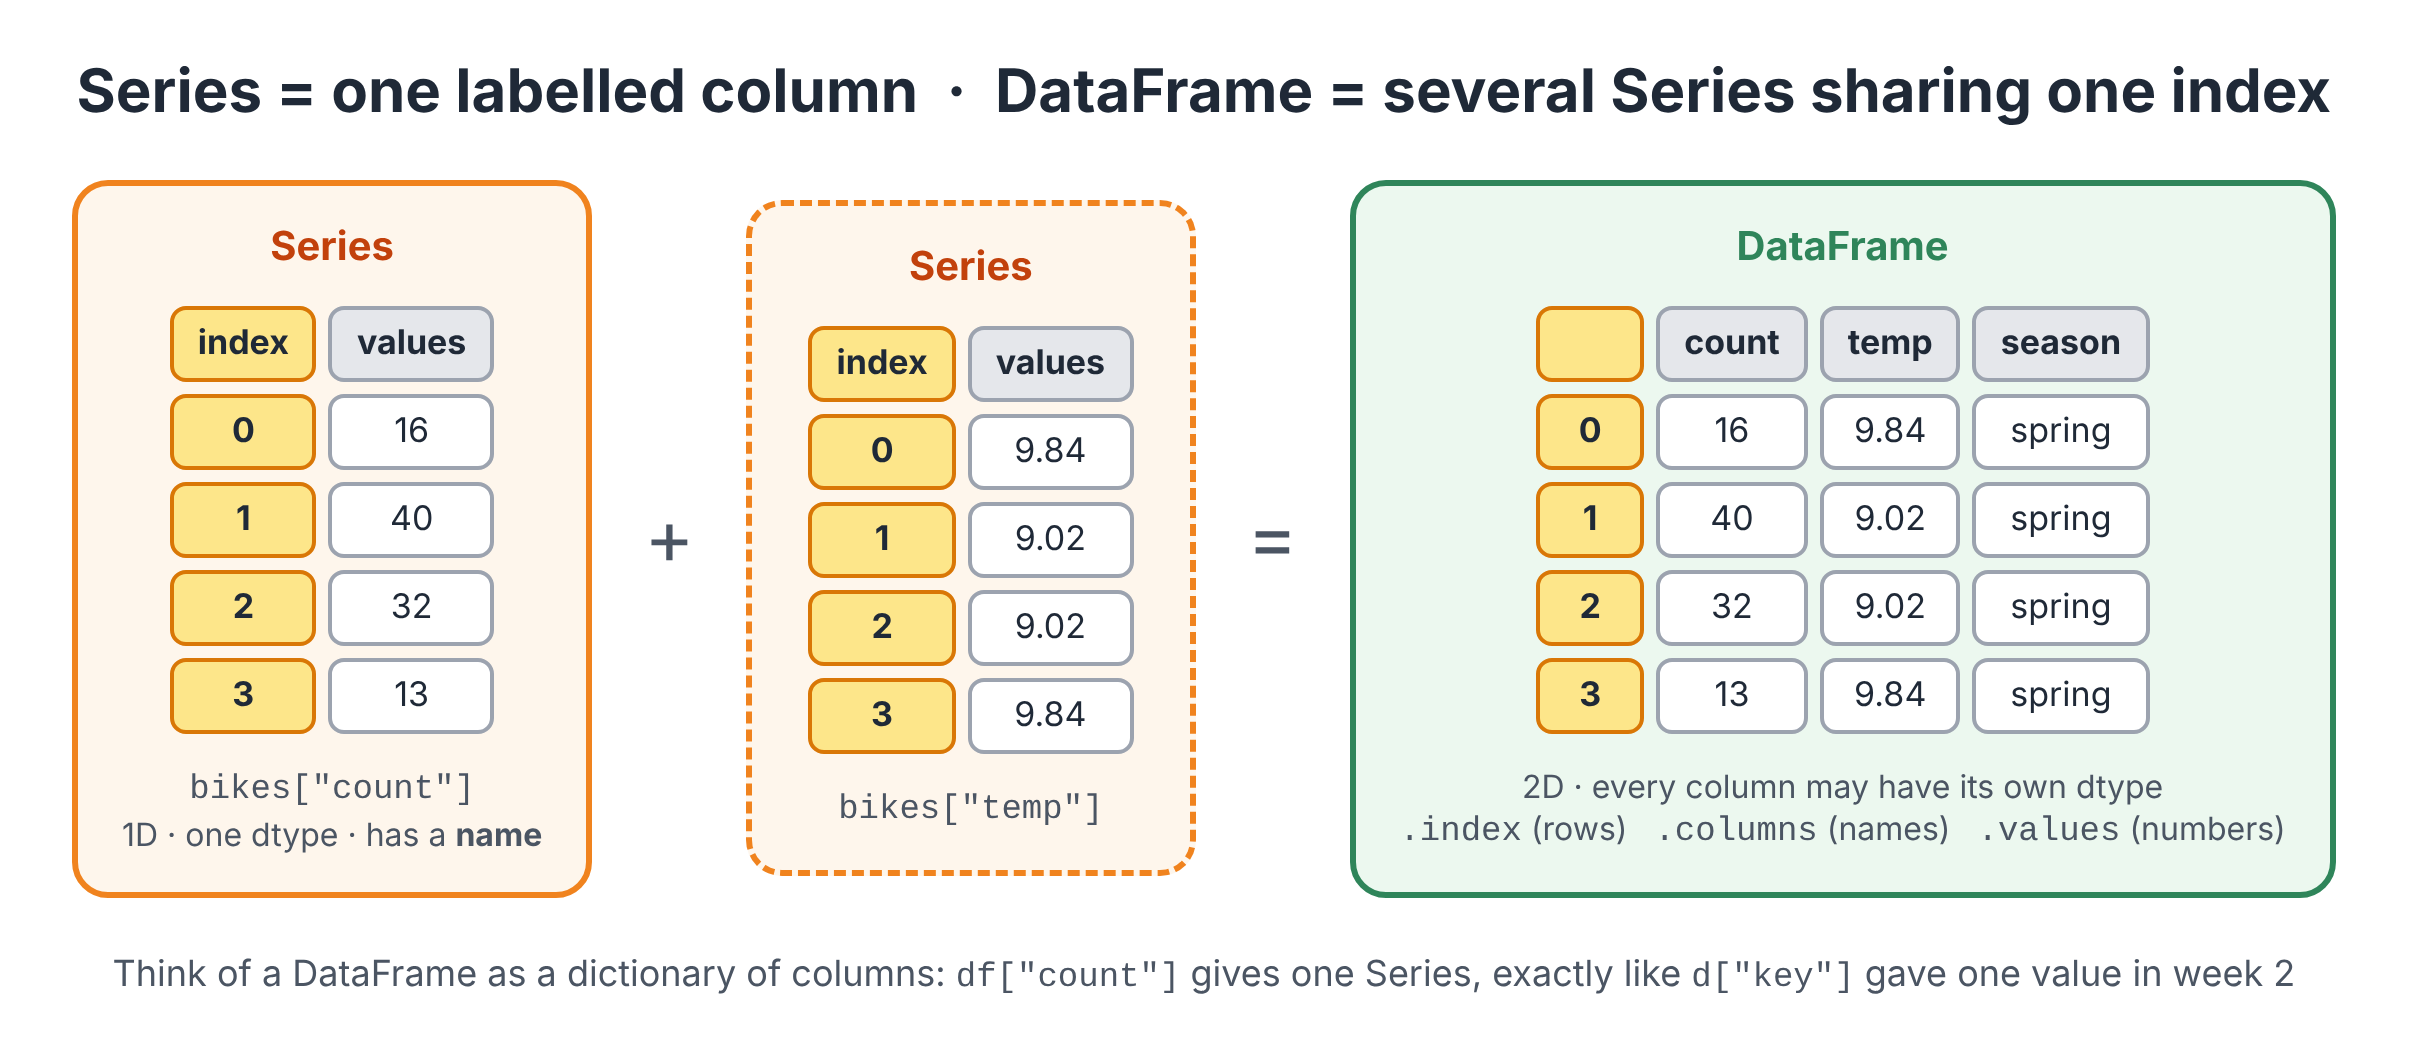

### Bikes dataset: Series

`bikes["count"]` - one column, picked with its name in square brackets, exactly like a value from a dictionary. The result is a **Series**: the values *and* the row labels (0, 1, 2, ...) *and* a name.

In [116]:
print(type(bikes["count"]))
bikes["count"].head()

<class 'pandas.core.series.Series'>


,count
0,16
1,40
2,32
3,13
4,1


In [117]:
len(bikes["count"])

10886

In [118]:
print(type(bikes["count"]))
bikes["count"].head(10)

<class 'pandas.core.series.Series'>


,count
0,16
1,40
2,32
3,13
4,1
5,1
6,2
7,3
8,8
9,14


### Bikes dataset: DataFrame

In [119]:
print(type(bikes))
bikes.head()

<class 'pandas.core.frame.DataFrame'>


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,01/01/2011 00:00,spring,0,0,1,9.84,14.395,81,0.0,3,13,16
1,01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32,40
2,01/01/2011 02:00,spring,0,0,1,9.02,13.635,80,0.0,5,27,32
3,01/01/2011 03:00,spring,0,0,1,9.84,14.395,75,0.0,3,10,13
4,01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0,0,1,1


Note the index!

The bold numbers on the left (0, 1, 2, 3, 4) are **not a column** - they are the **index**, the labels of the rows. pandas created it automatically when we loaded the file. .

### Series and DataFrames as dictionaries

### Series as a dictionary

In [120]:
bikes["count"].head().to_dict()

{0: 16, 1: 40, 2: 32, 3: 13, 4: 1}

### Dataframe row as a dictionary

In [121]:
bikes.iloc[0,:].to_dict()

{'datetime': '01/01/2011 00:00',
 'season': 'spring',
 'holiday': 0,
 'workingday': 0,
 'weather': 1,
 'temp': 9.84,
 'atemp': 14.395,
 'humidity': 81,
 'windspeed': 0.0,
 'casual': 3,
 'registered': 13,
 'count': 16}

This is the mental model: a **Series** is a dictionary *index label → value*; a **DataFrame row** is a dictionary *column name → value*; a **DataFrame** is a dictionary *column name → Series*. And it works in the other direction too - the easiest way to build a small table by hand is a dictionary of lists:

In [122]:
countries = pd.DataFrame({
    "country":    ["Latvia", "Estonia", "Lithuania", "Finland"],
    "capital":    ["Riga", "Tallinn", "Vilnius", "Helsinki"],
    "population": [1.9, 1.4, 2.9, 5.6]          # millions
})
countries

,country,capital,population
0,Latvia,Riga,1.9
1,Estonia,Tallinn,1.4
2,Lithuania,Vilnius,2.9
3,Finland,Helsinki,5.6


Every key becomes a **column name**, every list becomes a **column**; the lists must have the same length (one value per row). A column can be added later by assigning to a new name:

In [123]:
countries["area"] = [64.6, 45.3, 65.3, 338.4]     # thousand km²
countries

,country,capital,population,area
0,Latvia,Riga,1.9,64.6
1,Estonia,Tallinn,1.4,45.3
2,Lithuania,Vilnius,2.9,65.3
3,Finland,Helsinki,5.6,338.4


### YOUR TURN 1: your first table

1. Build a DataFrame `cities` from a dictionary with three columns: `city` (Riga, Daugavpils, Liepāja, Jelgava), `population` (605, 79, 67, 55 - thousands) and `founded` (1201, 1275, 1625, 1573). Show it.
2. Print only the `population` column. What is its `type`? And the `shape` of the whole table?
3. Add a column `country` with the value `"Latvia"` in every row (assign one string - pandas repeats it) and show the table again.

In [124]:
# YOUR CODE HERE:

In [125]:
# 1.
cities = pd.DataFrame({
    "city": ["Riga", "Daugavpils", "Liepāja", "Jelgava"],
    "population": [605, 79, 67, 55],
    "founded": [1201, 1275, 1625, 1573]
})
print(cities)

# 2.
print(cities["population"])
print(type(cities["population"]))        # Series
print(cities.shape)                      # (4, 3)

# 3.
cities["country"] = "Latvia"
print(cities)

         city  population  founded
0        Riga         605     1201
1  Daugavpils          79     1275
2     Liepāja          67     1625
3     Jelgava          55     1573
0    605
1     79
2     67
3     55
Name: population, dtype: int64
<class 'pandas.core.series.Series'>
(4, 3)
         city  population  founded country
0        Riga         605     1201  Latvia
1  Daugavpils          79     1275  Latvia
2     Liepāja          67     1625  Latvia
3     Jelgava          55     1573  Latvia


## Pandas Data Types

### Pandas / Python / NumPy  Data Types

| Pandas dtype    | Python type  | NumPy type                                                      | Usage                                        |
| --------------- | ------------ | --------------------------------------------------------------- | -------------------------------------------- |
| object          | str or mixed | string\_, unicode\_, mixed types                                | Text or mixed numeric and non-numeric values |
| int64           | int          | int\_, int8, int16, int32, int64, uint8, uint16, uint32, uint64 | Integer numbers                              |
| float64         | float        | float\_, float16, float32, float64                              | Floating point numbers                       |
| bool            | bool         | bool\_                                                          | True/False values                            |
| datetime64      | NA           | datetime64\[ns\]                                                | Date and time values                         |
| timedelta\[ns\] | NA           | NA                                                              | Differences between two datetimes            |
| category        | NA           | NA                                                              | Finite list of text values                   |

In NumPy the whole array had one dtype; in pandas **every column has its own**. The two new ones are `datetime64` (real dates - you can sort them, take the month, compute differences) and `category` (a column with a few repeated text values, e.g. `season`). Text columns are shown as `object`.

### Dataframe dtypes

In [126]:
bikes.dtypes

,0
datetime,object
season,object
holiday,int64
workingday,int64
weather,int64
temp,float64
atemp,float64
humidity,int64
windspeed,float64
casual,int64


A trap to remember: `datetime` was read as `object` (plain text!) - pandas did not know it is a date. "01/01/2011 00:00" sorted as text would put "01/02/2011" (February) before "02/01/2011" (January). We will convert it with `pd.to_datetime` in the *Transforming* section. A single column can be converted with `.astype()`, as in NumPy:

In [127]:
print(bikes["season"].astype("category").dtype)
print(bikes["temp"].astype(int).head(3).to_list())      # 9.84 -> 9 (cut, not rounded)

category
[9, 9, 9]


## Indexing

### Index properties

* Index is an immutable sequence, used for accessing any data point across the dataframe or series
* Rows and columns both have indexes: rows indices are called as __index__ and for __columns__ its general column names.
* Indexes support set operations like __union__, __intersection__, etc.
* Built-in indexes:
    * RangeIndex - a monotonic integer range.
    * NumericIndex - a sequence of numpy int/uint/float data.
    * CategoricalIndex - a sequence of fixed categories (strings)
    * DatetimeIndex - a sequence of datetime64 objects
    * TimedeltaIndex - a sequence of timedelta64 objects
    * PeriodIndex - a sequence of ordinal values indicating regular periods in time, e.g., period [Q-DEC]
    * IntervalIndex - a sequence of intervals, closed on the same side,e.g., (0, 1], (1, 2], (2, 3], (3, 4], (4, 5]

Every row has a position (0, 1, 2, ... - always) and an index label (whatever you choose); set_index makes a column the labels
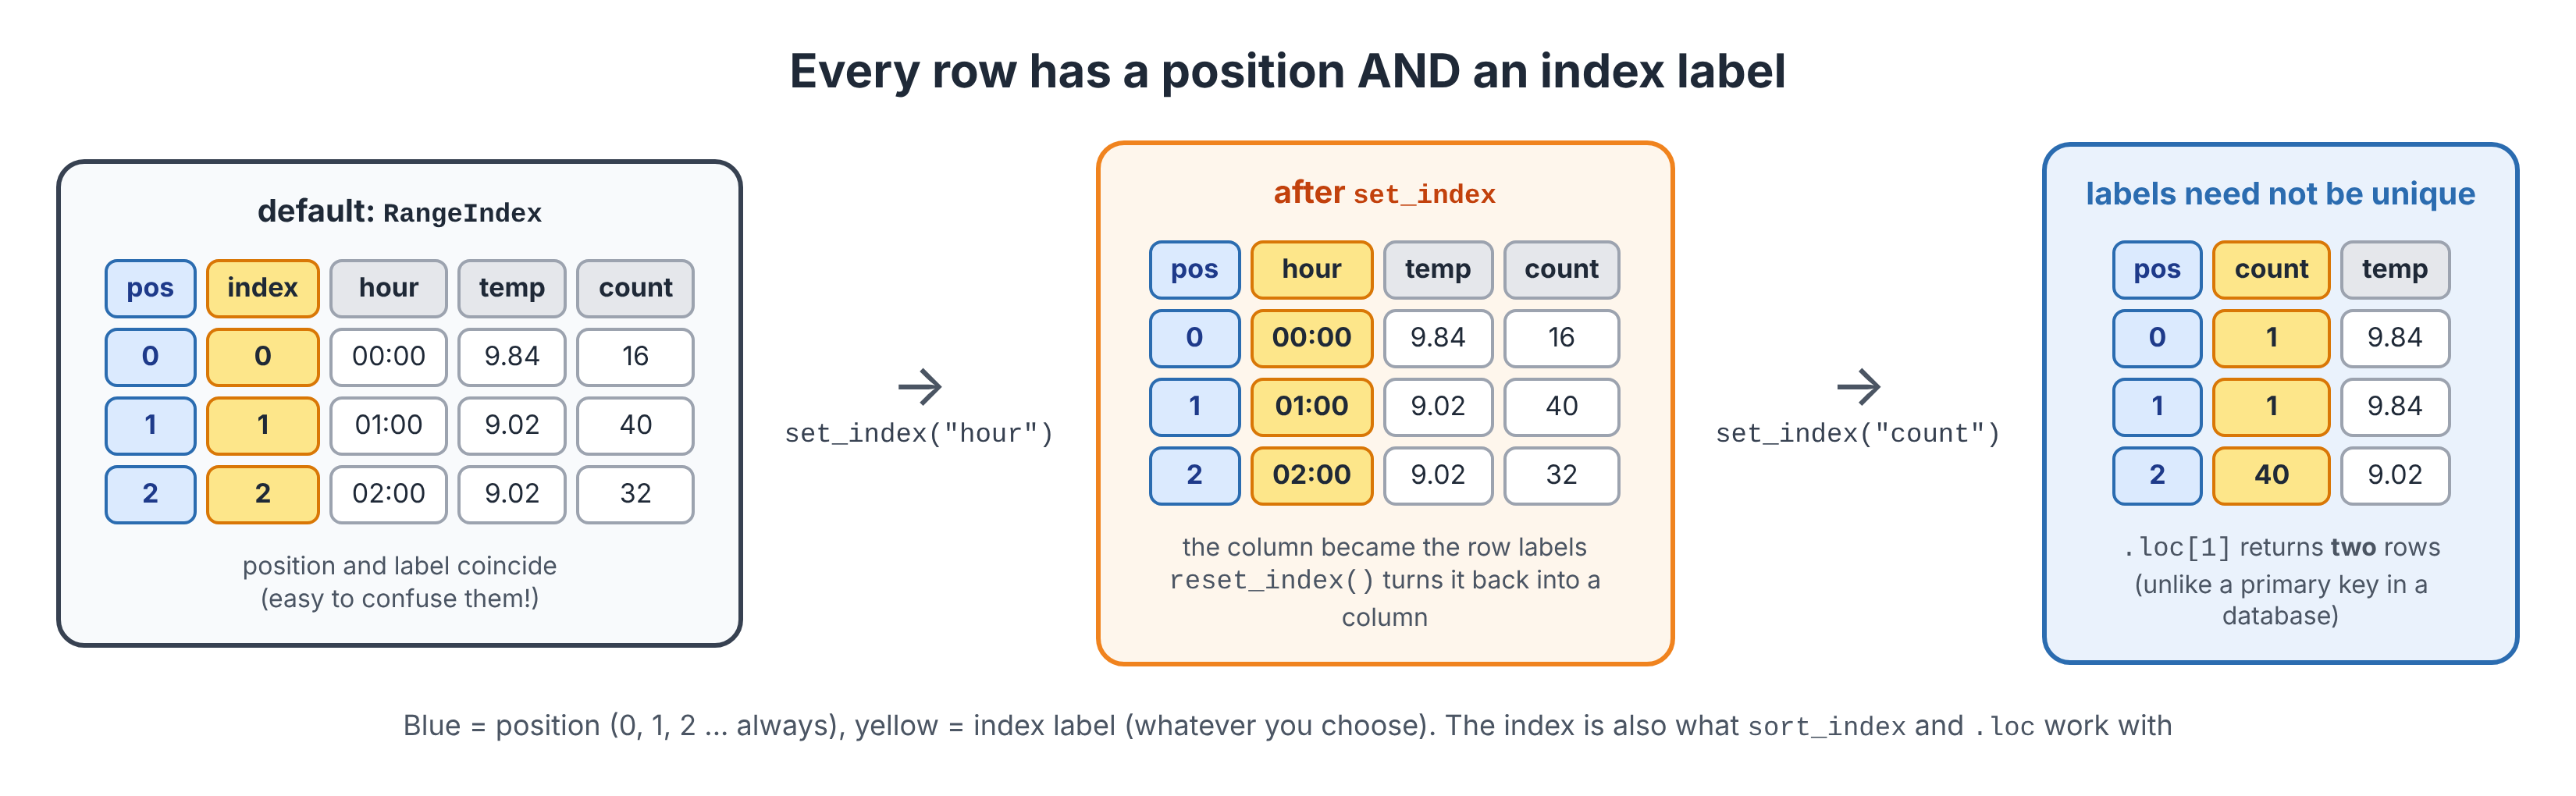

The list of index types above is **for reference** - you will meet `RangeIndex` (the default numbering) and `DatetimeIndex` (dates) in this course, the rest only when you need them. The **idea**: every row has a position *and* a label, and `.loc` / `.iloc` (next section) let you choose which one you mean.

Why does a table need an index at all? In Excel the row number *is* the label. In pandas the label can be something meaningful - a date, a country name, a student ID - so that you can say "give me the row **for Estonia**" instead of "give me row 1 and hope Estonia is still there after sorting". *Immutable* means you cannot change one label in place, but you can replace the whole index.

### Bikes: Indexes

In [128]:
bikes.index

RangeIndex(start=0, stop=10886, step=1)

In [129]:
bikes.columns

Index(['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp',
       'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count'],
      dtype='object')

`RangeIndex(start=0, stop=10886, step=1)` - the automatic numbering 0 ... 10885. `bikes.columns` is the *other* index - the column names. Both behave like lists: `list(bikes.columns)`, `len(bikes.index)`.

## Assigning index

Indexes are immutable, but can be reassigned:

In [130]:
bikes.index = bikes['count']
bikes.index

Index([ 16,  40,  32,  13,   1,   1,   2,   3,   8,  14,
       ...
       218, 237, 334, 562, 569, 336, 241, 168, 129,  88],
      dtype='int64', name='count', length=10886)

In [131]:
bikes.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,,,,,,,,,,,,
16,01/01/2011 00:00,spring,0,0,1,9.84,14.395,81,0.0,3,13,16
40,01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32,40
32,01/01/2011 02:00,spring,0,0,1,9.02,13.635,80,0.0,5,27,32
13,01/01/2011 03:00,spring,0,0,1,9.84,14.395,75,0.0,3,10,13
1,01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0,0,1,1


Now the row labels are the rental counts (16, 40, 32, ...) - and `count` is **still a column** too, because we only copied it into the index. Not a very useful index (the labels repeat and mean nothing as row names), but it shows that the index can be *any* sequence of the right length. The usual way is `set_index`, which **moves** a column into the index:

## Set/reset index

In [132]:
bikes.set_index("datetime", inplace=True)
bikes.head()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
datetime,,,,,,,,,,,
01/01/2011 00:00,spring,0,0,1,9.84,14.395,81,0.0,3,13,16
01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32,40
01/01/2011 02:00,spring,0,0,1,9.02,13.635,80,0.0,5,27,32
01/01/2011 03:00,spring,0,0,1,9.84,14.395,75,0.0,3,10,13
01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0,0,1,1


In [133]:
bikes.reset_index(inplace=True)
bikes.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,01/01/2011 00:00,spring,0,0,1,9.84,14.395,81,0.0,3,13,16
1,01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32,40
2,01/01/2011 02:00,spring,0,0,1,9.02,13.635,80,0.0,5,27,32
3,01/01/2011 03:00,spring,0,0,1,9.84,14.395,75,0.0,3,10,13
4,01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0,0,1,1


`set_index("datetime")` - the column `datetime` became the row labels (and disappeared from the columns); `reset_index()` - the labels went back into a column and the 0, 1, 2 ... numbering returned. `inplace=True` changes `bikes` itself; without it pandas returns a **new** DataFrame and leaves `bikes` untouched (then you would write `bikes = bikes.set_index(...)`).

## Reindexing

__.reindex()__  rearranges the data according to the new index, introducing missing values if any index values were not already present.

In [134]:
df = pd.DataFrame({"value":list(range(3))}, index = list(range(0,6,2)))
df

,value
0,0
2,1
4,2


In [135]:
df.reindex(index = list(range(0,6)))

,value
0,0.0
1,NaN
2,1.0
3,NaN
4,2.0
5,NaN


The small table had labels 0, 2, 4. We asked for labels 0 ... 5: the existing rows kept their values, the new labels (1, 3, 5) got `NaN` - *Not a Number*, pandas' marker for a **missing value** (the same `np.nan` as last week; note that `value` became `float` because of it). Typical use: a time series with gaps - reindex to all days, and the missing days appear explicitly.

In Pandas, there are two ways to select rows:
- .loc — selects rows by their index labels.
- .iloc — selects rows by their integer positions, starting from 0.

## Duplicated index values

Index values are not necessarily unique (unlike _primary keys_ in databases), so selecting by index can return multiple records

In [136]:
bikes.set_index("count", inplace=True)
bikes.loc[1,:].head() #returns a Series (1D), .head() displays the first 5 column values, not the first 5 rows.

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered
count,,,,,,,,,,,
1,01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0000,0,1
1,01/01/2011 05:00,spring,0,0,2,9.84,12.880,75,6.0032,0,1
1,02/01/2011 07:00,spring,0,0,2,16.40,20.455,76,12.9980,0,1
1,03/01/2011 04:00,spring,0,1,1,6.56,6.820,47,26.0027,0,1
1,04/01/2011 02:00,spring,0,1,1,5.74,7.575,63,8.9981,0,1


`.loc[1, :]` - "all rows **labelled** 1, all columns": every hour in which exactly one bike was rented. Several rows share the label 1, so we get several rows back. (We will use the same strange index in the next section, to see the difference between a label and a position.)

In [137]:
bikes.loc[1, :] # one row, all columns.
bikes.loc[:, 'atemp'] # all rows, the Count column.


,atemp
count,
16,14.395
40,13.635
32,13.635
13,14.395
1,14.395
...,...
336,19.695
241,17.425
168,15.910


In [138]:
bikes.iloc[1, :] # the second row by position, regardless of its index label.

,40
datetime,01/01/2011 01:00
season,spring
holiday,0
workingday,0
weather,1
temp,9.02
atemp,13.635
humidity,80
windspeed,0.0
casual,8


## Selectors

### Selectors

Selectors for NumPy arrays are straightforward - they always use the position (row number), e.g. [1,:] selector returns the second row

In [139]:
import numpy as np
np.eye(10)[1,:] # Creates an identity matrix

array([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.])

For __pandas__ dataframes there is a point of ambiguity here - Does "[1,:]" mean the second row or the rows with index values of 1?

The ambiguity is solved by __loc__ / __iloc__ selectors

loc = label (the row called 'Estonia'), iloc = integer position (the second row); both take [rows, columns]
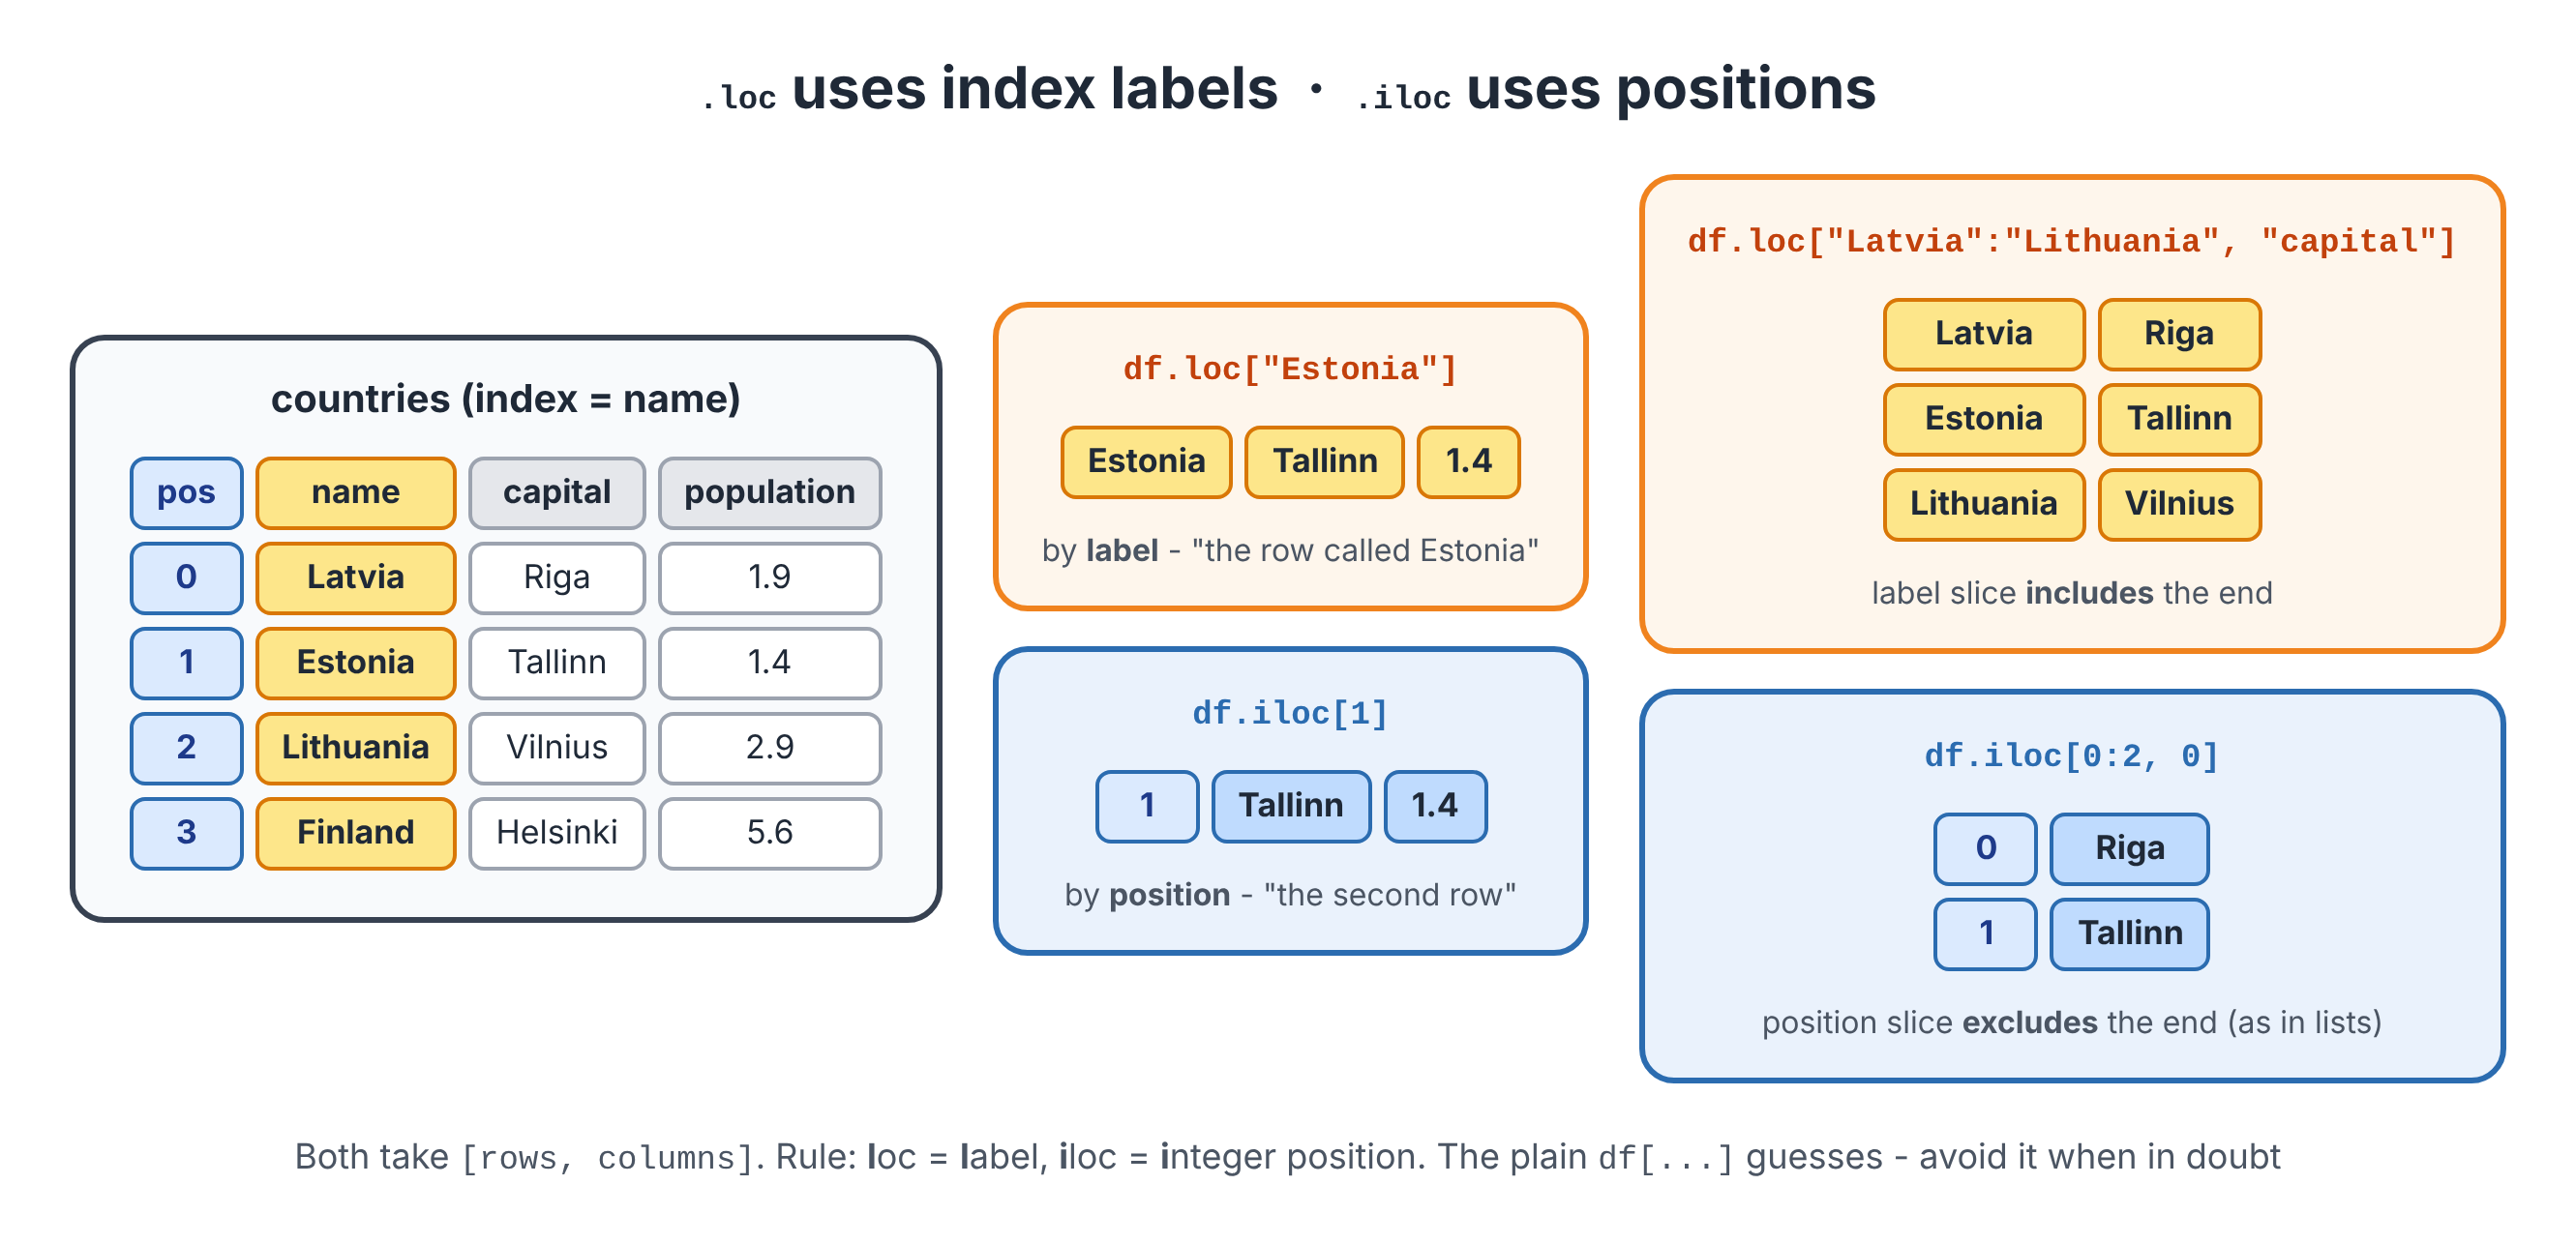

### Selectors loc/iloc

* __.loc__ selector works exclusively with index values
* __.iloc__ selector works exclusively with positions

In [140]:
bikes.iloc[[1]]
# Second row

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered
count,,,,,,,,,,,
40,01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32


In [141]:
bikes.loc[1].head()
# Rows with 1 rental

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered
count,,,,,,,,,,,
1,01/01/2011 04:00,spring,0,0,1,9.84,14.395,75,0.0000,0,1
1,01/01/2011 05:00,spring,0,0,2,9.84,12.880,75,6.0032,0,1
1,02/01/2011 07:00,spring,0,0,2,16.40,20.455,76,12.9980,0,1
1,03/01/2011 04:00,spring,0,1,1,6.56,6.820,47,26.0027,0,1
1,04/01/2011 02:00,spring,0,1,1,5.74,7.575,63,8.9981,0,1


Same number `1`, two different answers: `iloc[[1]]` → the row at **position** 1 (the second hour of the data, label 40); `loc[1]` → all rows with **label** 1. Memory aid: **i**loc = **i**nteger position, **l**oc = **l**abel.

Both accept `[rows, columns]`, and each part may be a single value, a list or a slice - as in NumPy:

In [142]:
print(bikes.iloc[0, 0])                       # one value: first row, first column
print(bikes.iloc[0:3, 0:2])                   # first 3 rows, first 2 columns (end excluded)
print(bikes.loc[1, ["temp", "humidity"]].head(3))   # rows labelled 1, two columns by name

01/01/2011 00:00
               datetime  season
count                          
16     01/01/2011 00:00  spring
40     01/01/2011 01:00  spring
32     01/01/2011 02:00  spring
        temp  humidity
count                 
1       9.84        75
1       9.84        75
1      16.40        76


On the small `countries` table the difference is easier to see. Let us make the country names the labels:

In [143]:
c = countries.set_index("country")
print(c.loc["Estonia"])                       # by label
print("---")
print(c.iloc[1])                              # by position - the same row here
print("---")
print(c.loc["Latvia":"Lithuania", "capital"]) # label slice INCLUDES the end
print("---")
print(c.iloc[0:2, 0])                         # position slice EXCLUDES the end

capital       Tallinn
population        1.4
area             45.3
Name: Estonia, dtype: object
---
capital       Tallinn
population        1.4
area             45.3
Name: Estonia, dtype: object
---
country
Latvia          Riga
Estonia      Tallinn
Lithuania    Vilnius
Name: capital, dtype: object
---
country
Latvia        Riga
Estonia    Tallinn
Name: capital, dtype: object


### Default selector

"Default" selector  (df[...]) is a smart one:
* if the row index contains integers, then numbers interpreted as index values, otherwise - as position.
* if only one element is provided it is interpreted as a column name
* if a bool mask is provided it is applied to rows

etc. - long list of _ifs_

In [144]:
bikes[1:2]

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered
count,,,,,,,,,,,
40,01/01/2011 01:00,spring,0,0,1,9.02,13.635,80,0.0,8,32


### Default selector

In [145]:
bikes["temp"]

,temp
count,
16,9.84
40,9.02
32,9.02
13,9.84
1,9.84
...,...
336,15.58
241,14.76
168,13.94


In [146]:
bikes[bikes["windspeed"]>50]

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered
count,,,,,,,,,,,
5,15/02/2011 01:00,spring,0,1,1,12.30,12.12,42,51.9987,0,5
171,19/02/2011 15:00,spring,0,0,1,18.04,21.97,16,50.0021,84,87
358,03/07/2011 17:00,fall,0,0,3,32.80,37.12,49,56.9969,181,177
181,03/07/2011 18:00,fall,0,0,3,32.80,37.12,49,56.9969,74,107


I recommend to use __loc__ / __iloc__ instead of the default selector for disambiguity

Three different things happened with the same square brackets: `bikes[1:2]` - a *slice* → **rows** by position (a slice in plain brackets is always positional, even here where the labels are integers - compare with `bikes.loc[1]`, which returned the rows *labelled* 1); `bikes["temp"]` - a *name* → a **column**; `bikes[bikes["windspeed"] > 50]` - a *True/False Series* → **rows where it is True**. That is exactly why the recommendation above says: use `.loc` / `.iloc` when you mean rows, and keep the plain brackets for picking a column or filtering. Filtering is the most important one for data analytics:

A comparison on a column gives a True/False Series; indexing with it keeps only the True rows - the labels are kept
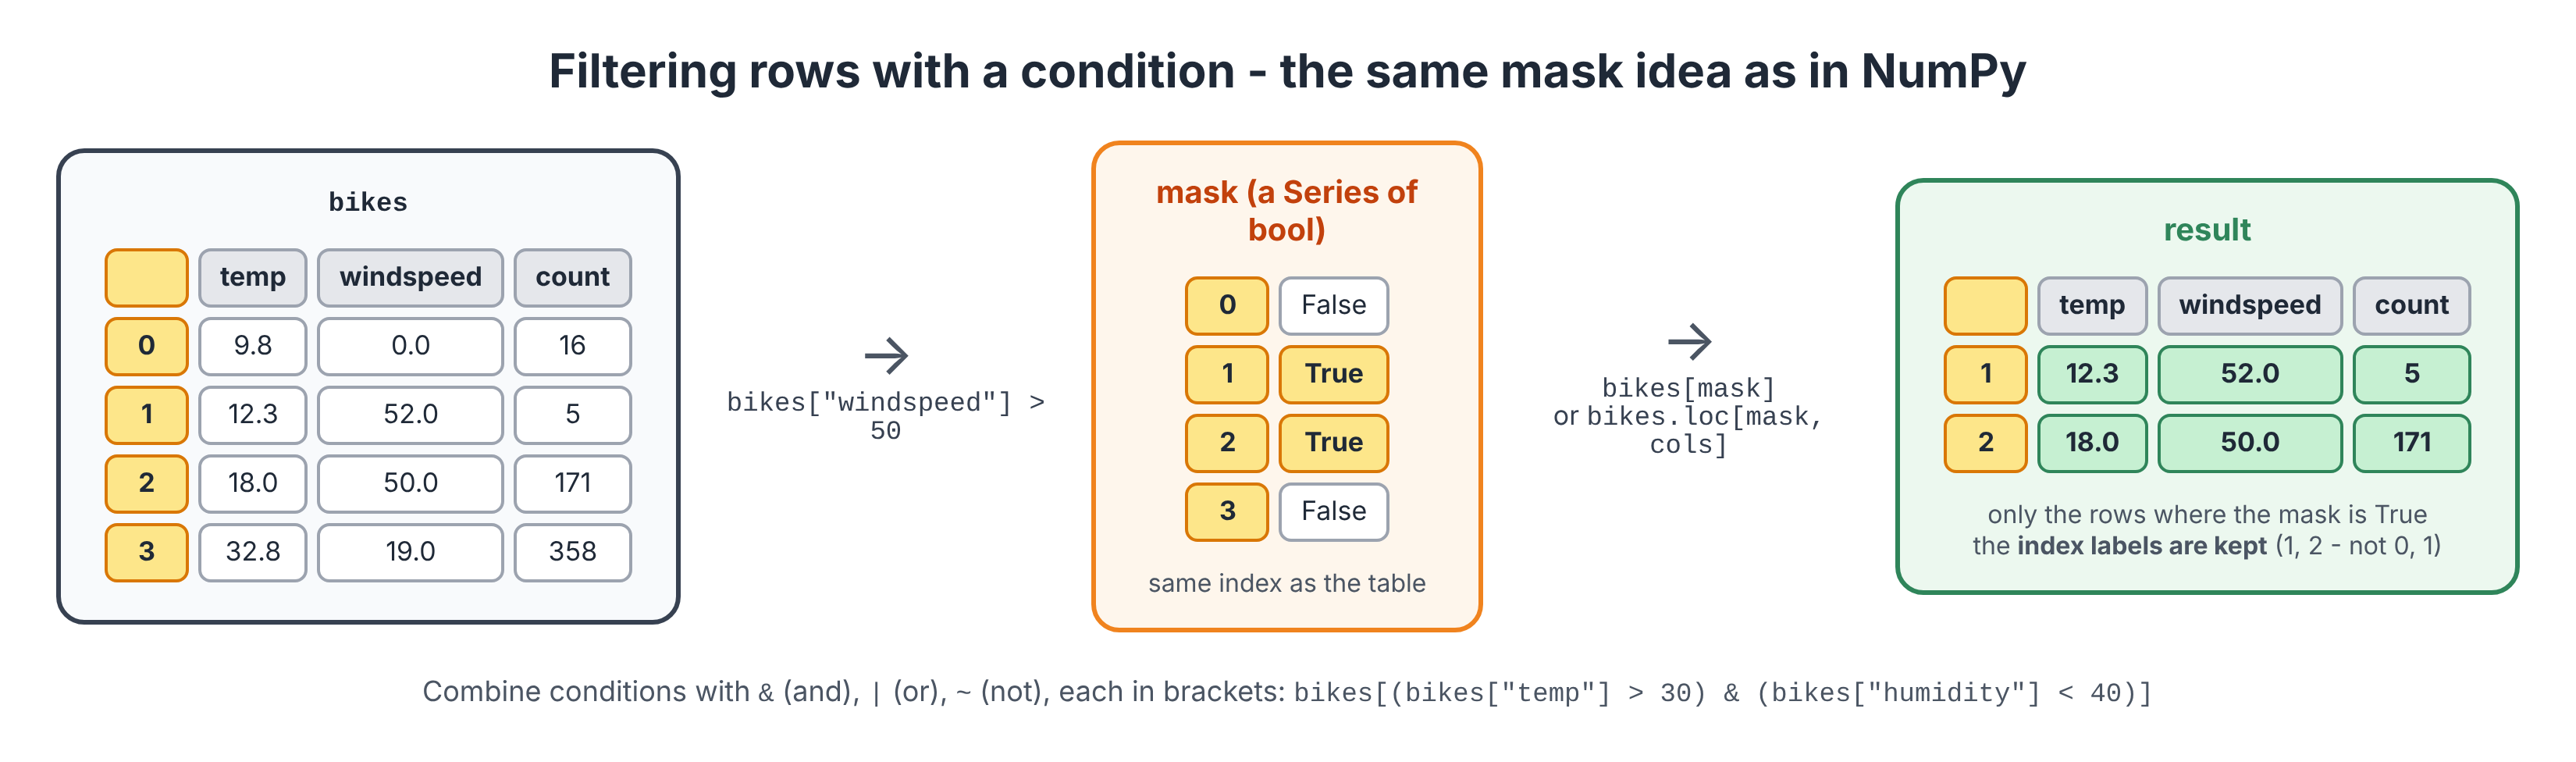

In [147]:
mask = bikes["windspeed"] >= 50          # a Series of True/False, one per row
print(mask.sum(), "very windy hours")    # True counts as 1
bikes.loc[mask, ["temp", "windspeed"]]   # loc with a mask + a list of columns

4 very windy hours


,temp,windspeed
count,,
5,12.30,51.9987
171,18.04,50.0021
358,32.80,56.9969
181,32.80,56.9969


In [148]:
# two conditions: hot AND windy - each condition in brackets, & for "and", | for "or", ~ for "not"
bikes.loc[(bikes["temp"] > 35) & (bikes["windspeed"] > 30), ["temp", "windspeed", "humidity"]]

,temp,windspeed,humidity
count,,,
491,35.26,35.0008,47
523,36.08,31.0009,44
526,36.90,31.0009,42
450,36.90,35.0008,37
383,35.26,31.0009,30


### YOUR TURN 2: picking rows and columns

To keep the exercise simple, work on a **copy with the default numbering** - `b = bikes.reset_index()` (`count` becomes a normal column again; `bikes` itself stays as it is).

1. Show the **first 3 rows** of `b` with `iloc`.
2. Show the columns `temp` and `count` for the rows **labelled 0 to 4** with `loc`. How many rows did you get - 4 or 5? Why?
3. How many hours had a temperature above 38 °C? (make a mask, use `.sum()`)
4. Show `datetime`, `temp` and `count` for those hours. Were they busy hours?

*Optional:* show the hours where `holiday` is 1 **and** `count` is above 500 (two conditions, each in brackets).

In [149]:
# YOUR CODE HERE:

In [150]:
b = bikes.reset_index()

# 1.
print(b.iloc[0:3])

# 2.  -> 5 rows: a label slice includes the end label (0,1,2,3,4)
print(b.loc[0:4, ["temp", "count"]])

# 3.
hot = b["temp"] > 38
print(hot.sum(), "hours")

# 4.  -> 14 hours, mostly 7 July 2012; 300-370 rentals - above the average (191), so yes
print(b.loc[hot, ["datetime", "temp", "count"]])

# optional
print(b.loc[(b["holiday"] == 1) & (b["count"] > 500), ["datetime", "count"]])

   count          datetime  season  holiday  workingday  weather  temp  \
0     16  01/01/2011 00:00  spring        0           0        1  9.84   
1     40  01/01/2011 01:00  spring        0           0        1  9.02   
2     32  01/01/2011 02:00  spring        0           0        1  9.02   

    atemp  humidity  windspeed  casual  registered  
0  14.395        81        0.0       3          13  
1  13.635        80        0.0       8          32  
2  13.635        80        0.0       5          27  
   temp  count
0  9.84     16
1  9.02     40
2  9.02     32
3  9.84     13
4  9.84      1
14 hours
              datetime   temp  count
2441  09/06/2011 15:00  38.54    104
8306  07/07/2012 11:00  38.54    367
8307  07/07/2012 12:00  39.36    342
8308  07/07/2012 13:00  39.36    360
8309  07/07/2012 14:00  39.36    308
8310  07/07/2012 15:00  39.36    306
8311  07/07/2012 16:00  41.00    294
8312  07/07/2012 17:00  39.36    279
8313  07/07/2012 18:00  38.54    277
8332  08/07/2012 13:00

## Sorting

sort_index orders by the row labels; sort_values('col') by a column - the whole row moves together
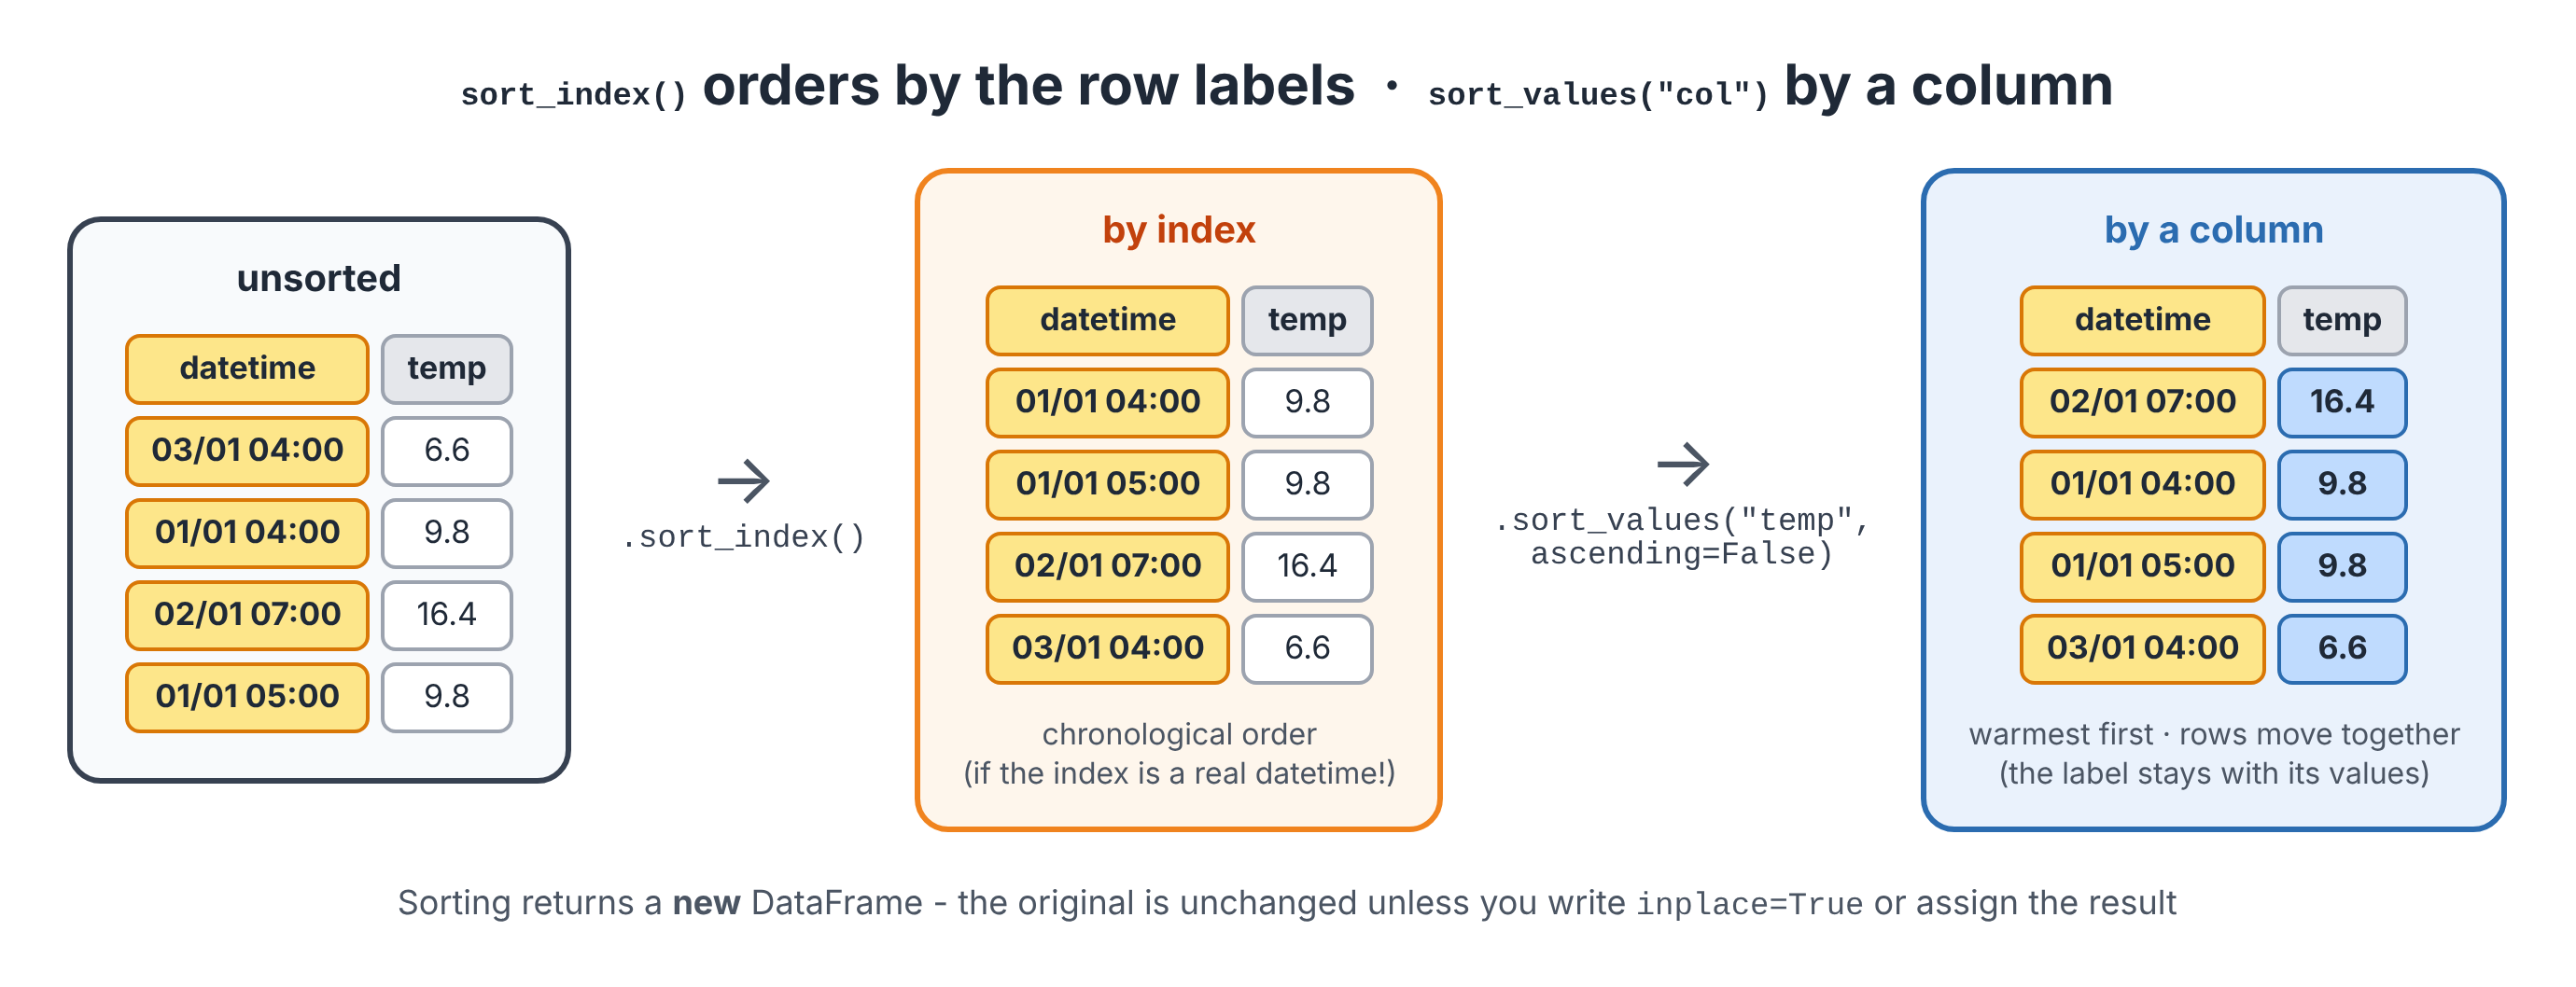

### Sorting by index

* __.sort_index__ for sorting by index

In [181]:
bikes.set_index("datetime").sort_index().head(3)

,count,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,comfort
datetime,,,,,,,,,,,,
2011-01-01 00:00:00,16,spring,0,0,1,9.84,14.395,81,0.0,3,13,cold
2011-01-01 01:00:00,40,spring,0,0,1,9.02,13.635,80,0.0,8,32,cold
2011-01-01 02:00:00,32,spring,0,0,1,9.02,13.635,80,0.0,5,27,cold


### Sorting by column values

* __.sort_values__ for sorting by column values

In [182]:
bikes.set_index("datetime").sort_values("temp", ascending=False).head(3)

,count,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,comfort
datetime,,,,,,,,,,,,
2012-07-07 16:00:00,294,fall,0,0,1,41.00,43.18,19,11.0014,102,192,hot
2012-07-07 14:00:00,308,fall,0,0,2,39.36,43.18,30,8.9981,105,203,hot
2012-07-07 13:00:00,360,fall,0,0,2,39.36,43.18,31,16.9979,116,244,hot


Reading the chain from left to right: *make `datetime` the index → sort by it → show the first 3 rows*. Each method returns a new DataFrame, so the next method can be called on the result - a **method chain**. `ascending=False` = largest first; the hottest hour of the data set was 41 °C on 7 July 2012.

Careful: `datetime` is still **text**, so `sort_index()` sorted it **alphabetically**, character by character. The first day looks right, but after "01/01/2011 23:00" comes "01/01/2012 00:00" - a year later - and only then "02/01/2011":

In [153]:
bikes.set_index("datetime").sort_index().iloc[22:26, 0:3]      # rows 22-25 of the sorted table

,season,holiday,workingday
datetime,,,
01/01/2011 22:00,spring,0,0
01/01/2011 23:00,spring,0,0
01/01/2012 00:00,spring,0,0
01/01/2012 01:00,spring,0,0


That is why a date column must be converted to a real date type before sorting - we do it in the next section. To sort by two columns, pass a list: `sort_values(["season", "temp"])`.

## Transforming column values

## Creating new / Transforming column values

* Direct function call for a Series or using __apply__ (__apply__ tranforming all values in the dataframe and  selecting the axis and transform columns or rows)

Arithmetic on a whole column, apply() with your own function per value, map() over every cell of a DataFrame
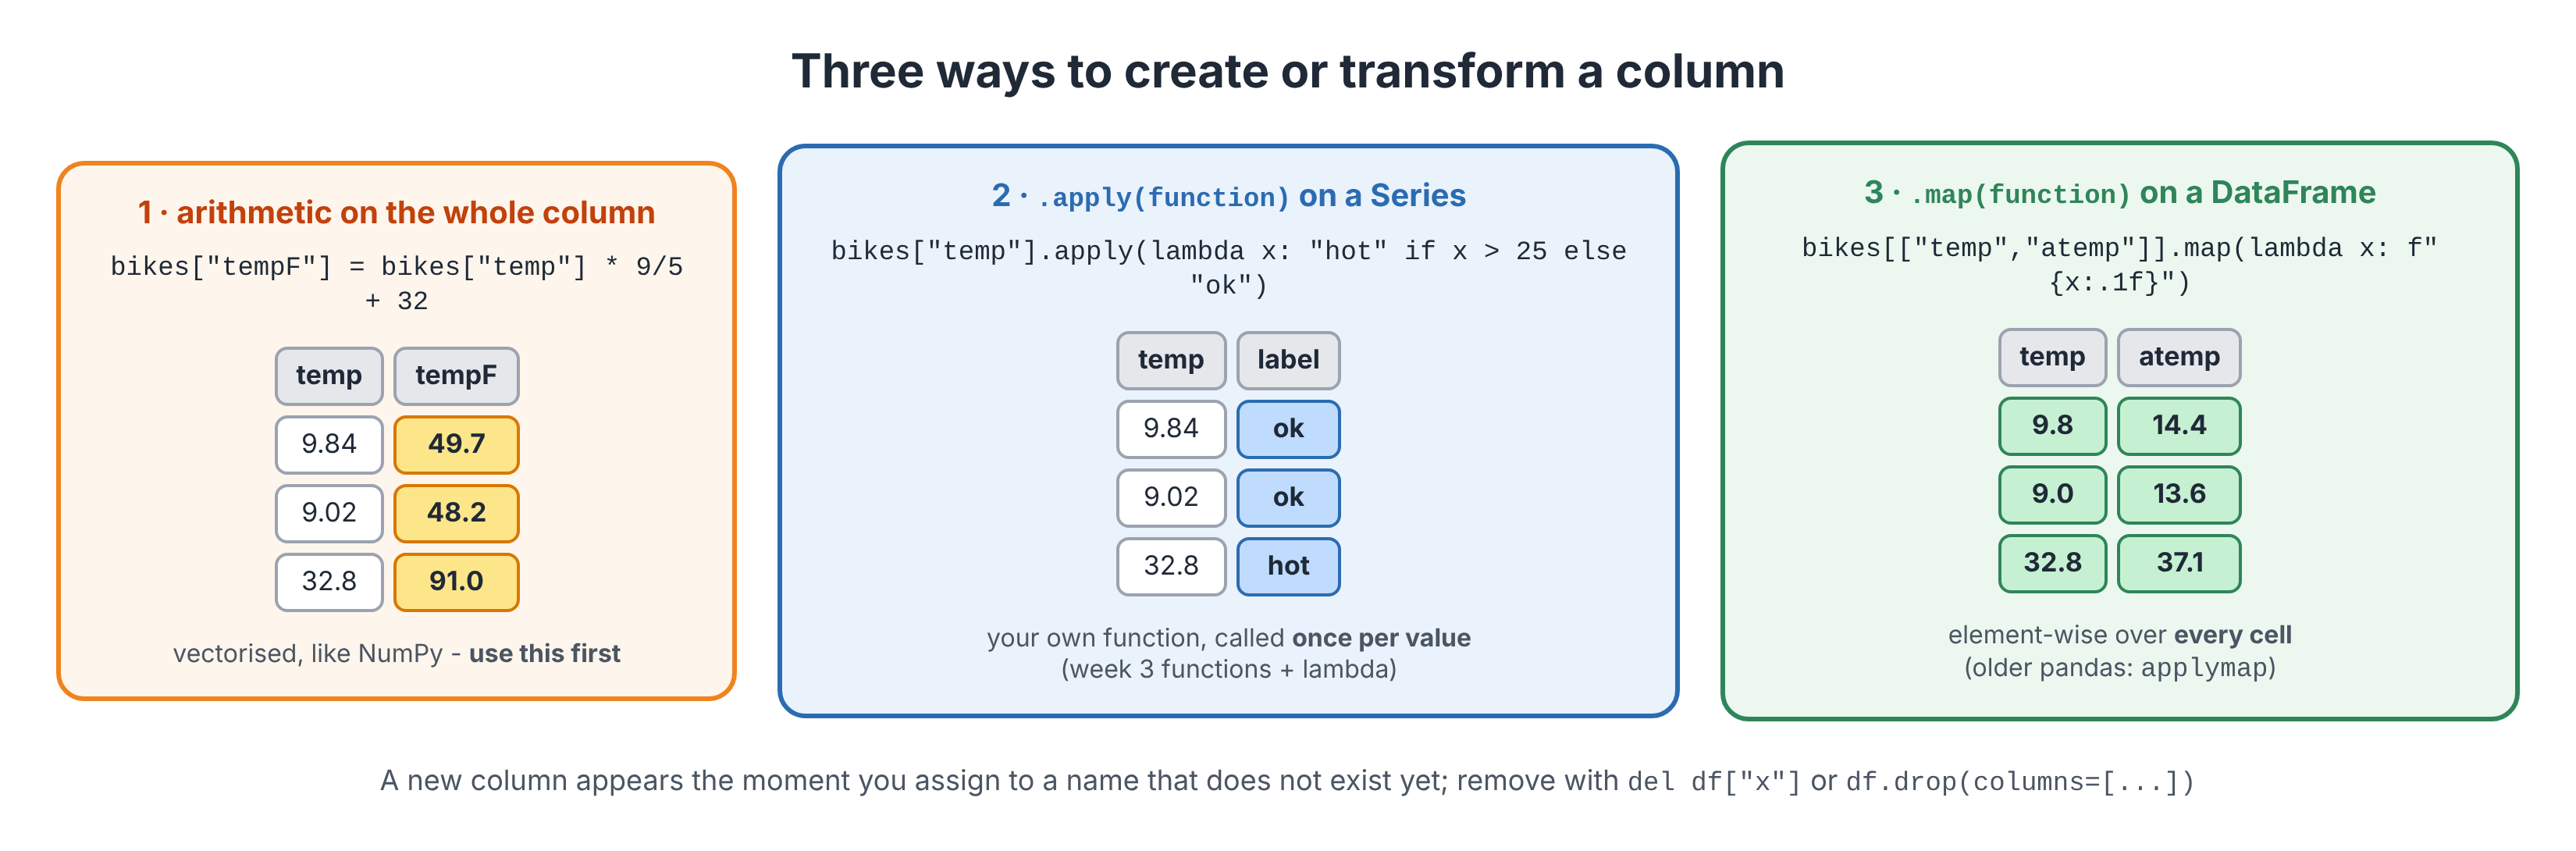

In [184]:
bikes["datetime"] = pd.to_datetime(bikes["datetime"], format='%d/%m/%Y %H:%M')
bikes["tempF"] = bikes["temp"] * 9.0/5 + 32 #Direct call
bikes["atempF"] = bikes["atemp"].apply(lambda x: x*9.0/5 +32)
bikes.loc[bikes["windspeed"]>50,["datetime","temp","tempF","atemp","atempF"]]

,datetime,temp,tempF,atemp,atempF
760,2011-02-15 01:00:00,12.30,54.140,12.12,53.816
868,2011-02-19 15:00:00,18.04,64.472,21.97,71.546
2755,2011-07-03 17:00:00,32.80,91.040,37.12,98.816
2756,2011-07-03 18:00:00,32.80,91.040,37.12,98.816


Three things happened:

* `pd.to_datetime(..., format='%d/%m/%Y %H:%M')` converted the text into real dates. The format string says how the text looks: `%d` day, `%m` month, `%Y` 4-digit year, `%H:%M` hours:minutes (the same codes as `strftime` in week 3). Check `bikes.dtypes` now - `datetime64[ns]`.
* `bikes["temp"] * 9.0/5 + 32` - **arithmetic on the whole column** at once (vectorised, as in NumPy). Assigning to a new name creates the column `tempF`.
* `.apply(lambda x: ...)` calls your function **once for every value**. Here it gives the same result as the arithmetic, only slower - but `apply` can do anything a function can: `if`, string methods, dictionary look-ups.

In [185]:
# apply with a function that returns text - a label for every hour
def comfort(t):
    if t < 10:
        return "cold"
    elif t < 25:
        return "ok"
    else:
        return "hot"

bikes["comfort"] = bikes["temp"].apply(comfort)
bikes[["temp", "comfort"]].head()

,temp,comfort
0,9.84,cold
1,9.02,cold
2,9.02,cold
3,9.84,cold
4,9.84,cold


## Creating new / Transforming column values

* Using __applymap__ (element-wise function)

`applymap` applies a function to **every cell** of a DataFrame (not only one column). Here we format the numbers as text with 2 decimals. (In pandas 2.1+ the method was renamed to `DataFrame.map`; in Colab's pandas 2.2 `applymap` still works but prints a *FutureWarning* - the yellow message under the cell is a hint, not an error. In pandas 3 the old name is gone - the small cell below keeps the example working everywhere.)

In [186]:
if not hasattr(pd.DataFrame, "applymap"):          # pandas 3+: applymap was renamed to map
    pd.DataFrame.applymap = pd.DataFrame.map

In [188]:
bikes["tempF_formatted"] = bikes[["tempF"]].applymap(lambda x: f'{x:.2f}')
bikes.loc[bikes["windspeed"]>50,["datetime","tempF","tempF_formatted"]]

/tmp/ipykernel_490/3656800809.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  bikes["tempF_formatted"] = bikes[["tempF"]].applymap(lambda x: f'{x:.2f}')


,datetime,tempF,tempF_formatted
760,2011-02-15 01:00:00,54.140,54.14
868,2011-02-19 15:00:00,64.472,64.47
2755,2011-07-03 17:00:00,91.040,91.04
2756,2011-07-03 18:00:00,91.040,91.04


### Dropping columns / rows


del — a Python statement that deletes a column directly from the original DataFrame.



drop() — a Pandas method that removes rows or columns and returns a new DataFrame by default.

* Using __del__ statement

In [189]:
del bikes["tempF_formatted"]

* Using __drop__ method

In [160]:
bikes.drop(columns=["atempF","tempF"], inplace=True)
bikes.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,comfort
count,,,,,,,,,,,,
16,2011-01-01 00:00:00,spring,0,0,1,9.84,14.395,81,0.0,3,13,cold
40,2011-01-01 01:00:00,spring,0,0,1,9.02,13.635,80,0.0,8,32,cold
32,2011-01-01 02:00:00,spring,0,0,1,9.02,13.635,80,0.0,5,27,cold
13,2011-01-01 03:00:00,spring,0,0,1,9.84,14.395,75,0.0,3,10,cold
1,2011-01-01 04:00:00,spring,0,0,1,9.84,14.395,75,0.0,0,1,cold


`del` removes one column immediately; `drop(columns=[...])` removes several at once (and `drop(index=[...])` removes rows by label). Both are irreversible - if you need the column again, load the data again.

### YOUR TURN 3: new columns

1. Create a column `humidity10` with the humidity rounded to tens (10, 20, 30, ...). Hint: `(bikes["humidity"] / 10).round() * 10`. Show `humidity` and `humidity10` for the first 5 rows. (Lab 5, exercise 2.2 asks for the same with temperature.)
2. Sort the table by `temp` descending and show the 3 warmest hours - columns `datetime`, `temp`, `humidity10`.
3. Remove the column `humidity10` again.

*Optional (or homework, YOUR TURN 5):* a column `wind` with the text `"windy"` when `windspeed` is above 20 and `"calm"` otherwise - a small function + `apply`.

In [161]:
# YOUR CODE HERE:

In [162]:
# 1.
bikes["humidity10"] = (bikes["humidity"] / 10).round() * 10
print(bikes[["humidity", "humidity10"]].head())

# 2.
print(bikes.sort_values("temp", ascending=False)[["datetime", "temp", "humidity10"]].head(3))

# 3.
del bikes["humidity10"]

# optional
def wind_label(w):
    if w > 20:
        return "windy"
    return "calm"
print(bikes["windspeed"].apply(wind_label).head())

       humidity  humidity10
count                      
16           81        80.0
40           80        80.0
32           80        80.0
13           75        80.0
1            75        80.0
                 datetime   temp  humidity10
count                                       
294   2012-07-07 16:00:00  41.00        20.0
308   2012-07-07 14:00:00  39.36        30.0
360   2012-07-07 13:00:00  39.36        30.0
count
16    calm
40    calm
32    calm
13    calm
1     calm
Name: windspeed, dtype: object


## Statistics

### Statistics
Pandas DataFrames provide many frequently used methods:

Statistics are computed column by column: mean() gives a Series, describe() gives a table of eight numbers per column
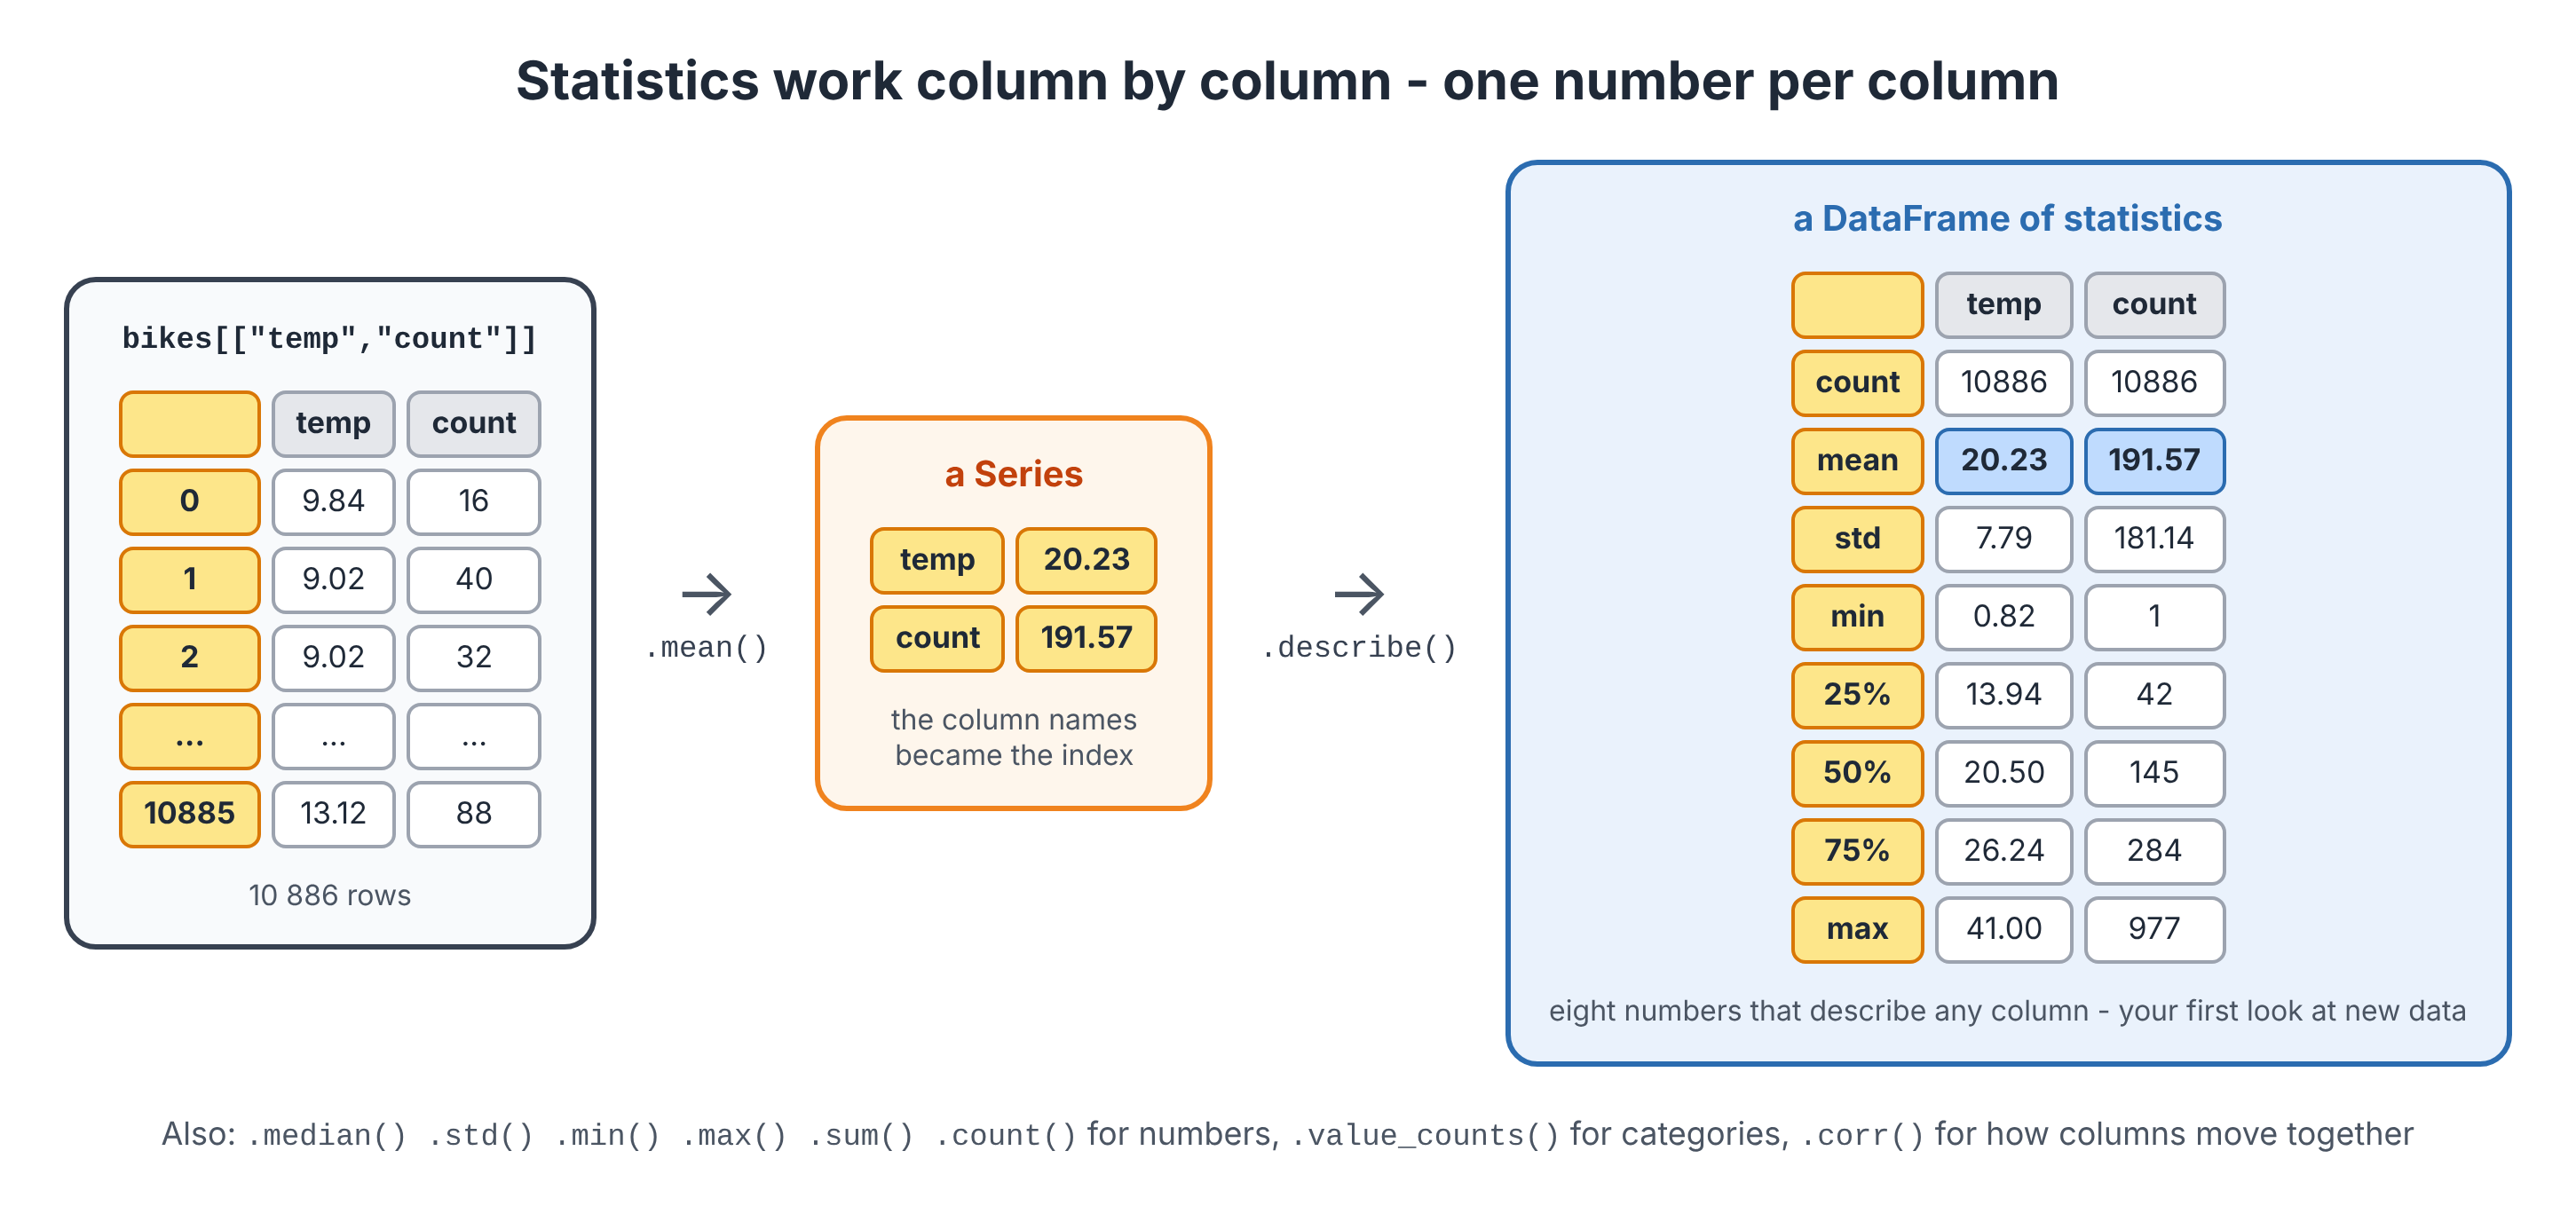

In [190]:
bikes.reset_index(inplace=True)
bikes[["temp", "humidity", "windspeed", "count"]].mean()

,0
temp,20.230860
humidity,61.886460
windspeed,12.799395
count,191.574132


In [164]:
bikes[["temp", "humidity", "windspeed", "count"]].max()

,0
temp,41.0000
humidity,100.0000
windspeed,56.9969
count,977.0000


First `reset_index` - `count` was still the index since the *Duplicated index values* example; now it is a normal column again, with the default numbering back. Then: `bikes[["temp", "humidity", "windspeed", "count"]]` - a **list of names** inside the brackets (note the double brackets) selects several columns → a smaller DataFrame. `.mean()` then works **down every column** (`axis=0`, as in NumPy) and returns a Series: the column names became the index. Also available: `.median() .std() .min() .sum() .count()`, and `.round(2)` to tidy the output.

### Statistics

In [165]:
bikes[["temp", "humidity", "windspeed", "count"]].describe()

,temp,humidity,windspeed,count
count,10886.00000,10886.000000,10886.000000,10886.000000
mean,20.23086,61.886460,12.799395,191.574132
std,7.79159,19.245033,8.164537,181.144454
min,0.82000,0.000000,0.000000,1.000000
25%,13.94000,47.000000,7.001500,42.000000
50%,20.50000,62.000000,12.998000,145.000000
75%,26.24000,77.000000,16.997900,284.000000
max,41.00000,100.000000,56.996900,977.000000


In [166]:
bikes[["temp", "humidity", "windspeed", "count"]].corr()

,temp,humidity,windspeed,count
temp,1.000000,-0.064949,-0.017852,0.394454
humidity,-0.064949,1.000000,-0.318607,-0.317371
windspeed,-0.017852,-0.318607,1.000000,0.101369
count,0.394454,-0.317371,0.101369,1.000000


`describe()` is the first thing to run on any new data set: count, mean, standard deviation, min, the quartiles (25 % of the hours had fewer than 42 rentals, half had fewer than 145) and max - a sanity check for impossible values (humidity 0 %? a count of 977 in one hour?).

`corr()` - the **correlation** between every pair of columns, from -1 to 1: how strongly two columns move together. `temp` and `count` are 0.39 - higher temperatures are **associated with** higher rental counts in this data set, moderately; `humidity` and `count` are -0.32 - more humid hours tend to have fewer rentals. The diagonal is 1 - a column with itself.

**Careful with the words:** a correlation describes an *association*, it does not prove that temperature alone *causes* the extra rentals - warm hours are also daytime hours, summer hours, holiday hours. Separating such effects is what modelling (block 8) is for. For now: *"is associated with"*, not *"causes"*.

### Counting categories

For a text column the useful statistic is *how many of each*: `value_counts()`.

In [191]:
print(bikes["season"].value_counts())
print(bikes["comfort"].value_counts(normalize=True).round(2))     # as fractions

season
winter    2734
summer    2733
fall      2733
spring    2686
Name: count, dtype: int64
comfort
ok      0.56
hot     0.32
cold    0.12
Name: proportion, dtype: float64


(The result is a Series named `count` - pandas' word for "how many", not our `count` column.) `value_counts()` is also the quickest check for typos in a text column: "Spring" and "spring" would appear as two categories.

## Plots

### Plots

Pandas DataFrames provide many frequently used plots:
* histograms
* pie charts
* boxplots
* lines
* scatters
etc.

pandas uses the **matplotlib** library behind the scenes (lesson 6.1 is about it); for a quick look at the data `.plot.<kind>()` on a Series or a DataFrame is enough. The rule: *histogram* - how are the values of **one** column distributed; *line* - a value **over time**; *box* - compare the spread of **several** columns; *bar* - counts per category; *scatter* - two numeric columns against each other.

### Histogram

<Axes: ylabel='Frequency'>

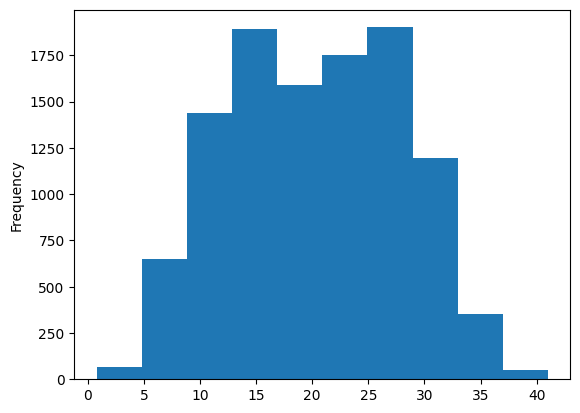

In [192]:
bikes["temp"].plot.hist()

Horizontal axis - temperature, vertical - how many hours fell into each bin. `bins=30` gives finer bars; `bikes["count"].plot.hist(bins=30)` shows that most hours have few rentals and a long tail of busy hours.

### Lines

<Axes: xlabel='datetime'>

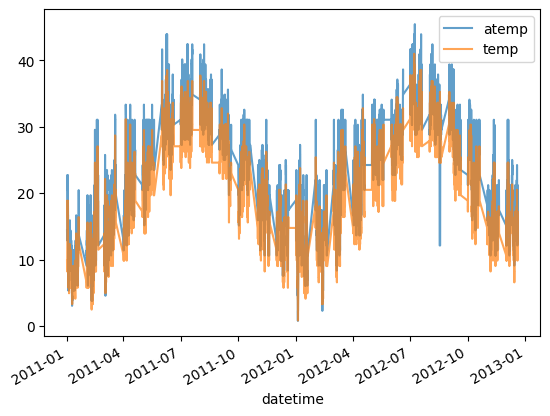

In [193]:
bikes.set_index("datetime").sort_index()[["atemp","temp"]].plot.line(alpha=0.7)

Now that `datetime` is a real date, `set_index` + `sort_index` puts the hours in chronological order and the x-axis shows the dates. Two columns → two lines; `alpha=0.7` makes them a bit transparent so that both are visible. The yearly cycle of the two years is clearly seen.

### Boxplots

<Axes: >

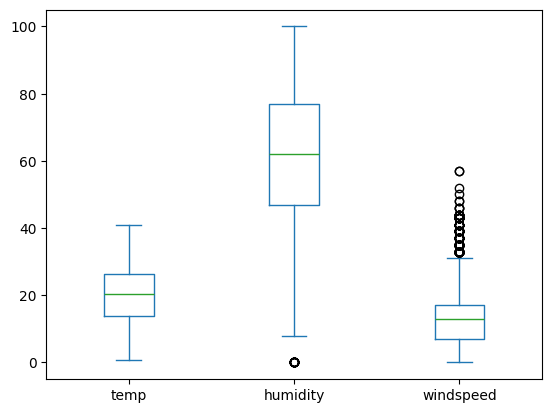

In [194]:
bikes[["temp", "humidity", "windspeed"]].plot.box()

One box per column: the box is the middle 50 % of the values (the 25 % - 75 % from `describe()`), the line inside is the median, the whiskers the usual range, the circles **outliers** - the very windy hours above ~35 km/h.

### Bars and scatters

<Axes: xlabel='season'>

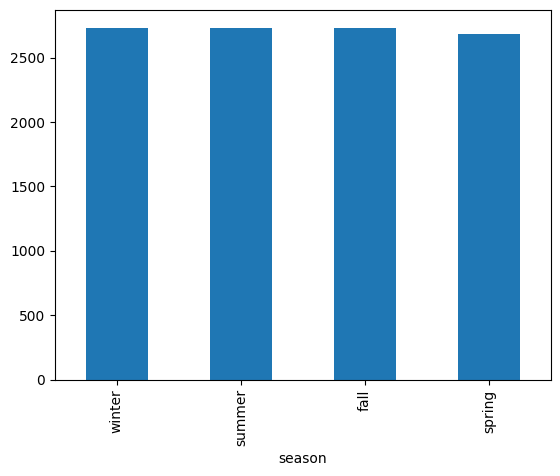

In [195]:
bikes["season"].value_counts().plot.bar()          # counts per category

<Axes: xlabel='temp', ylabel='count'>

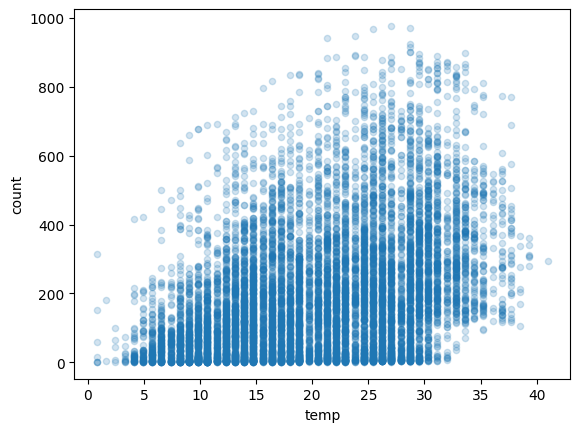

In [196]:
bikes.plot.scatter(x="temp", y="count", alpha=0.2)   # two numeric columns - the correlation of 0.39 made visible

### Answering the question of the day

*Does the temperature influence how many bikes are rented?* We now have everything to answer in plain English:

* `corr()` → 0.39: a moderate positive association between temperature and rentals.
* the scatter plot → rentals rise with temperature up to about 30 °C, and the spread is huge at every temperature - temperature alone explains only a part.
* `value_counts()` / `describe()` → the data covers all four seasons evenly, so the result is not an artefact of one season.

**Conclusion:** in this data set warmer hours are associated with more rentals, but the temperature is only one of several factors (time of day, working day, weather type) - claiming that it *causes* the demand would need a model that holds the other factors constant (block 8).

### YOUR TURN 4: a first look at the rentals

1. Run `describe()` on the `count` column only. What was the busiest hour (max)? What is the median? Why are the mean (191) and the median (145) so different?
2. Compute the mean of `casual` and `registered` rentals (two columns, one call). Which group rents more, and roughly how many times more? Write the answer as **one sentence** a manager would understand.
3. Draw a histogram of `count` with 30 bins. Does its shape agree with your answer to question 1?
4. Draw a bar plot of the number of hours per `comfort` category (`value_counts()` + `plot.bar()`).

*Optional:* a box plot of `count` - are there outliers?

In [173]:
# YOUR CODE HERE:

count    10886.000000
mean       191.574132
std        181.144454
min          1.000000
25%         42.000000
50%        145.000000
75%        284.000000
max        977.000000
Name: count, dtype: float64
casual         36.021955
registered    155.552177
dtype: float64


<Axes: ylabel='Frequency'>

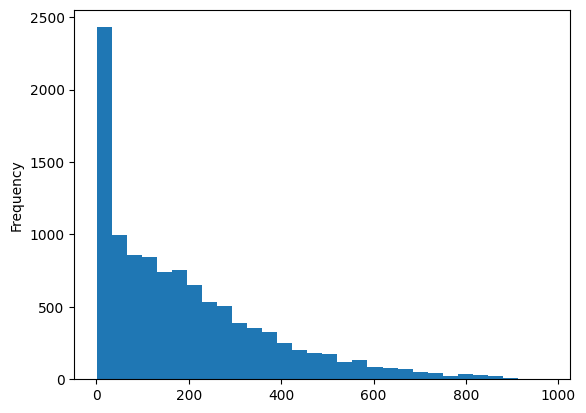

In [174]:
# 1.  max 977, median 145; mean > median because a few very busy hours pull the mean up (a long right tail)
print(bikes["count"].describe())

# 2.  registered ~155 per hour vs casual ~36 - registered users rent about 4 times more;
#     "Most demand comes from registered users; casual riders are a small share of hourly rentals."
print(bikes[["casual", "registered"]].mean())

# 3.  yes - most hours have few rentals, a long tail of busy hours to the right
bikes["count"].plot.hist(bins=30)

<Axes: xlabel='comfort'>

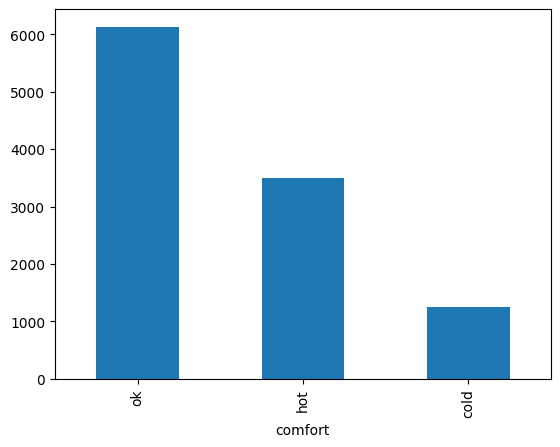

In [175]:
# 4.
bikes["comfort"].value_counts().plot.bar()

<Axes: >

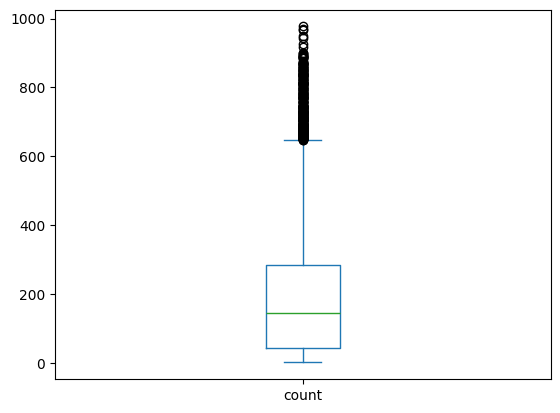

In [176]:
# optional - yes, many very busy hours above the upper whisker
bikes["count"].plot.box()

### YOUR TURN 5: a small country analysis - HOMEWORK (Lab 5, exercise 1 rehearsal)

Start from a new DataFrame `eu` built from a dictionary: `country` (Latvia, Estonia, Lithuania, Poland, Sweden), `capital` (Riga, Tallinn, Vilnius, Warsaw, Stockholm), `population` (1.9, 1.4, 2.9, 36.7, 10.6 - millions), `gdp` (43, 41, 79, 811, 585 - billion €).

1. Add a column `gdp_per_capita` (thousand € per person) and round it to 1 decimal.
2. Add a column `eu_member_since` with the dates `"2004-05-01", "2004-05-01", "2004-05-01", "2004-05-01", "1995-01-01"` and convert it to a real date type with `pd.to_datetime`. Check `eu.dtypes`.
3. Add a column `size` with the text `"large"` when the population is above 5 million and `"small"` otherwise (a small function + `apply`).
4. Set `country` as the index.
5. Show the 2 countries with the highest GDP per capita.
6. Show the row for Poland with `loc` and the same row with `iloc`.
7. Show the countries with a population below 3 million (a mask).
8. Draw a bar plot of `gdp_per_capita`. In one sentence: what does the chart tell you?
9. Save the table to `eu.csv` and load it back with `read_csv` - which column did you get extra, and how do you avoid it?

In [177]:
# YOUR CODE HERE:

country                    object
capital                    object
population                float64
gdp                         int64
gdp_per_capita            float64
eu_member_since    datetime64[ns]
dtype: object
             capital  population  gdp  gdp_per_capita eu_member_since   size
country                                                                     
Latvia          Riga         1.9   43            22.6      2004-05-01  small
Estonia      Tallinn         1.4   41            29.3      2004-05-01  small
Lithuania    Vilnius         2.9   79            27.2      2004-05-01  small
Poland        Warsaw        36.7  811            22.1      2004-05-01  large
Sweden     Stockholm        10.6  585            55.2      1995-01-01  large
           capital  population  gdp  gdp_per_capita eu_member_since   size
country                                                                   
Sweden   Stockholm        10.6  585            55.2      1995-01-01  large
Estonia    Tallinn

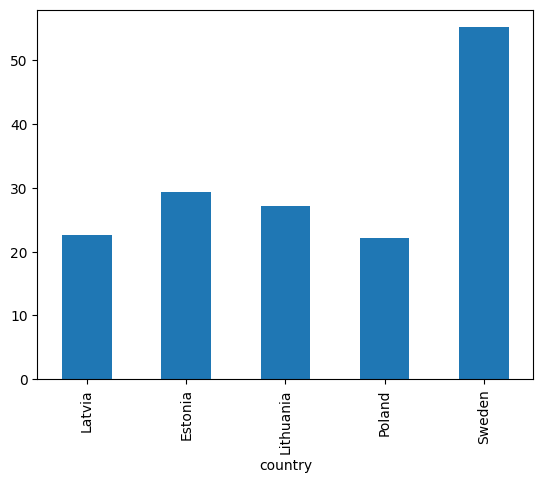

In [178]:
eu = pd.DataFrame({
    "country": ["Latvia", "Estonia", "Lithuania", "Poland", "Sweden"],
    "capital": ["Riga", "Tallinn", "Vilnius", "Warsaw", "Stockholm"],
    "population": [1.9, 1.4, 2.9, 36.7, 10.6],
    "gdp": [43, 41, 79, 811, 585]
})

# 1.
eu["gdp_per_capita"] = (eu["gdp"] / eu["population"]).round(1)

# 2.
eu["eu_member_since"] = pd.to_datetime(["2004-05-01", "2004-05-01", "2004-05-01", "2004-05-01", "1995-01-01"])
print(eu.dtypes)

# 3.
def size_label(p):
    if p > 5:
        return "large"
    return "small"
eu["size"] = eu["population"].apply(size_label)

# 4.
eu = eu.set_index("country")
print(eu)

# 5.
print(eu.sort_values("gdp_per_capita", ascending=False).head(2))

# 6.
print(eu.loc["Poland"])
print(eu.iloc[3])

# 7.
print(eu[eu["population"] < 3])

# 8.  Sweden is far ahead; the three Baltic states are close to each other; Poland is lowest per person despite the largest economy
eu["gdp_per_capita"].plot.bar()

# 9.
eu.to_csv("eu.csv")                              # the index (country) is written as the first column
back = pd.read_csv("eu.csv")                     # -> 'country' is a normal column again
print(back.columns.to_list())
back = pd.read_csv("eu.csv", index_col=0)        # index_col=0 puts it back into the index
print(back.index.to_list())

## Conclusion

### Conclusion

Pandas is a pretty library with data manipulation routines:
1. Efficient data storage and computations - via NumPy
2. Indexes - database-like
3. Functions for data loading - easier than direct file reading/parsing
4. Functions for statistics - cover most frequently used descriptive statistics
5. Functions for plots - easier than plotting with specialised libraries
6. Flexibility - easy to extend with required data manipulation routines

## Summary

* `pd.read_csv(path_or_url)` → **DataFrame**; `.head() .tail() .shape .info() .dtypes` - the first look; `.to_csv(..., index=False)` to save
* **Series** = one labelled column (`df["col"]`), **DataFrame** = several Series sharing one **index**; build one from a dictionary of lists
* every row has a **position** (0, 1, 2 ...) and an **index label**; `set_index("col")` / `reset_index()`; labels need not be unique; `reindex` introduces `NaN`
* `.loc[labels, columns]` and `.iloc[positions, columns]` - label slices include the end, position slices do not; avoid the plain `df[...]` when in doubt
* **filter** with a mask: `df[df["col"] > x]`, `df.loc[mask, cols]`; combine with `& | ~` in brackets; `mask.sum()` counts
* `sort_index()`, `sort_values("col", ascending=False)`; methods return a new DataFrame → **chains**
* new columns: `df["new"] = df["a"] * 2`, `df["a"].apply(func)`, `df[[...]].applymap(func)` (new name: `.map`); `pd.to_datetime(col, format=...)`; `del df["x"]`, `df.drop(columns=[...])`
* statistics column by column: `.mean() .max() .describe() .corr()`, `value_counts()` for categories, `isna().sum()` for gaps; correlation = association, not causation
* plots in one line: `.plot.hist() .plot.line() .plot.box() .plot.bar() .plot.scatter(x=, y=)`

# Thank you